In [1]:
!pip install -q pyspark==3.5.1 graphframes networkx scikit-learn matplotlib seaborn
print("Selesai. Jalankan Runtime > Restart session.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.0/317.0 MB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.5/200.5 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 11.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.
Selesai. Jalankan Runtime > Restart session.


### Bagian I: Data Ingestion & Preprocessing

In [2]:
import os

BASE = "/content/data_lake"
RAW_DATACO = BASE + "/raw/dataco"
PROCESSED = BASE + "/processed/fact_orders"
ANALYTICS = BASE + "/analytics"
CKPT = BASE + "/checkpoints"

folders = [
    "raw/dataco", "raw/abo/images", "raw/abo/metadata",
    "staging/dataco_cleaned", "staging/abo_category_index",
    "processed/fact_orders", "analytics", "checkpoints",
]
for f in folders:
    os.makedirs(os.path.join(BASE, f), exist_ok=True)

print("Data lake dibuat di:", BASE)
for f in folders:
    print("  -", f)

Data lake dibuat di: /content/data_lake
  - raw/dataco
  - raw/abo/images
  - raw/abo/metadata
  - staging/dataco_cleaned
  - staging/abo_category_index
  - processed/fact_orders
  - analytics
  - checkpoints


### Dataset DataCo

In [3]:
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d shashwatwork/dataco-smart-supply-chain-for-big-data-analysis \
    -p /content/data_lake/raw/dataco --unzip

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis
License(s): CC0-1.0
100% 25.7M/25.7M [00:00<00:00, 96.9MB/s]



In [4]:
!ls -la /content/data_lake/raw/dataco

total 186892
drwxr-xr-x 2 root root     4096 Oct 22 06:53 .
drwxr-xr-x 4 root root     4096 Oct 22 06:52 ..
-rw-r--r-- 1 root root 95910149 Oct 22 06:53 DataCoSupplyChainDataset.csv
-rw-r--r-- 1 root root     3444 Oct 22 06:53 DescriptionDataCoSupplyChain.csv
-rw-r--r-- 1 root root 95446364 Oct 22 06:53 tokenized_access_logs.csv


### Dataset Amazon Berkeley Objects (ABO)

In [5]:
!wget -q https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-listings.tar \
    -O /content/data_lake/raw/abo/metadata/abo-listings.tar

!tar -xf /content/data_lake/raw/abo/metadata/abo-listings.tar \
    -C /content/data_lake/raw/abo/metadata

!find /content/data_lake/raw/abo/metadata -name "listings_*.json.gz" | wc -l

16


In [6]:
!wget -q https://amazon-berkeley-objects.s3.amazonaws.com/images/metadata/images.csv.gz \
    -O /content/data_lake/raw/abo/images/images_metadata.csv.gz

!gunzip -f /content/data_lake/raw/abo/images/images_metadata.csv.gz
!head -5 /content/data_lake/raw/abo/images/images_metadata.csv

image_id,height,width,path
010-mllS7JL,106,106,14/14fe8812.jpg
01dkn0Gyx0L,122,122,da/daab0cad.jpg
01sUPg0387L,111,111,d2/d2daaae9.jpg
1168jc-5r1L,186,186,3a/3a4e88e6.jpg


## 4. Inisialisasi Spark

Satu SparkSession untuk seluruh notebook, sudah dikonfigurasi untuk kebutuhan Bagian II
(paket GraphFrames, memori driver, partisi shuffle, parser tanggal legacy).

In [7]:
import time, json, warnings
warnings.filterwarnings("ignore")

from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import IntegerType

spark = (
    SparkSession.builder
    .appName("DataCo_Assignment_I_dan_II")
    .master("local[*]")
    .config("spark.jars.packages", "graphframes:graphframes:0.8.3-spark3.5-s_2.12")
    .config("spark.driver.memory", "10g")
    .config("spark.sql.shuffle.partitions", "32")
    .config("spark.sql.legacy.timeParserPolicy", "LEGACY")
    .getOrCreate()
)
spark.sparkContext.setCheckpointDir(CKPT)
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

Spark version: 3.5.1


### Cleaning DataCo

In [8]:
dataco = spark.read.csv(
    RAW_DATACO + "/DataCoSupplyChainDataset.csv",
    header=True, inferSchema=True, encoding="iso-8859-1"
)

print("Jumlah baris awal:", dataco.count())
dataco.printSchema()

Jumlah baris awal: 180519
root
 |-- Type: string (nullable = true)
 |-- Days for shipping (real): integer (nullable = true)
 |-- Days for shipment (scheduled): integer (nullable = true)
 |-- Benefit per order: double (nullable = true)
 |-- Sales per customer: double (nullable = true)
 |-- Delivery Status: string (nullable = true)
 |-- Late_delivery_risk: integer (nullable = true)
 |-- Category Id: integer (nullable = true)
 |-- Category Name: string (nullable = true)
 |-- Customer City: string (nullable = true)
 |-- Customer Country: string (nullable = true)
 |-- Customer Email: string (nullable = true)
 |-- Customer Fname: string (nullable = true)
 |-- Customer Id: integer (nullable = true)
 |-- Customer Lname: string (nullable = true)
 |-- Customer Password: string (nullable = true)
 |-- Customer Segment: string (nullable = true)
 |-- Customer State: string (nullable = true)
 |-- Customer Street: string (nullable = true)
 |-- Customer Zipcode: integer (nullable = true)
 |-- Departmen

In [9]:
dataco_clean = (
    dataco
    .dropDuplicates()
    .withColumn("category_key", F.lower(F.trim(F.col("Category Name"))))
    .filter(F.col("Order Item Quantity").isNotNull())
)

print("Jumlah baris setelah dibersihkan:", dataco_clean.count())
dataco_clean.write.mode("overwrite").parquet(BASE + "/staging/dataco_cleaned")

Jumlah baris setelah dibersihkan: 180519


In [10]:
dataco_clean.select("category_key").distinct().orderBy("category_key").show(50, truncate=False)

+--------------------+
|category_key        |
+--------------------+
|accessories         |
|as seen on  tv!     |
|baby                |
|baseball & softball |
|basketball          |
|books               |
|boxing & mma        |
|cameras             |
|camping & hiking    |
|cardio equipment    |
|cds                 |
|children's clothing |
|cleats              |
|computers           |
|consumer electronics|
|crafts              |
|dvds                |
|electronics         |
|fishing             |
|fitness accessories |
|garden              |
|girls' apparel      |
|golf apparel        |
|golf bags & carts   |
|golf balls          |
|golf gloves         |
|golf shoes          |
|health and beauty   |
|hockey              |
|hunting & shooting  |
|indoor/outdoor games|
|kids' golf clubs    |
|lacrosse            |
|men's clothing      |
|men's footwear      |
|men's golf clubs    |
|music               |
|pet supplies        |
|shop by sport       |
|soccer              |
|sporting g

### Loading Metadata ABO

In [11]:
abo_meta = spark.read.json(BASE + "/raw/abo/metadata/listings/metadata/listings_*.json.gz")

abo_index = (
    abo_meta
    .select(
        F.col("item_id"),
        F.element_at(F.col("product_type.value"), 1).alias("product_type"),
        F.col("main_image_id").alias("image_id"),
    )
    .withColumn("category_key_abo", F.lower(F.trim(F.col("product_type"))))
    .dropna(subset=["category_key_abo"])
)

print("Listing ABO terbaca :", abo_index.count())
print("Kategori unik ABO   :", abo_index.select("category_key_abo").distinct().count())

Listing ABO terbaca : 147702
Kategori unik ABO   : 576


### Sampling Gambar Per Kategori ABO

In [12]:
w = Window.partitionBy("category_key_abo").orderBy(F.rand())

abo_sample = (
    abo_index
    .withColumn("rn", F.row_number().over(w))
    .filter(F.col("rn") == 1)
    .select("category_key_abo", "image_id")
)

abo_sample.write.mode("overwrite").parquet(BASE + "/staging/abo_category_index")
abo_sample.show(20, truncate=False)

+----------------------------+-----------+
|category_key_abo            |image_id   |
+----------------------------+-----------+
|abis_beauty                 |51LQNnuvDTL|
|abis_book                   |61yxyQLcW7L|
|abis_drugstore              |51o28ex7yzL|
|abis_electronics            |61OnkGVhMWL|
|abis_home_improvement       |71fZWbC6XbL|
|abis_kitchen                |61WDkH-6fUL|
|abis_lawn_and_garden        |61P5MTOQ0oL|
|abis_pet_products           |61vI4W+yHFL|
|abis_video_games            |712uahiKeEL|
|accessory                   |91zTqtNkk8L|
|accessory_or_part_or_supply |61QjD5--qYL|
|agricultural_supplies       |61o954HWXdL|
|air_compressor              |71v6o+eJLdL|
|air_conditioner             |51FRhgrPx6L|
|air_fryer                   |71H8btY1jlL|
|air_mattress                |51HdVZV2l5L|
|air_pump                    |91JmEf-HsiL|
|air_purifier                |81Wyoq03gPL|
|amazon_book_reader_accessory|31IFtBNZgaL|
|amazon_tablet_accessory     |81wLb-Grw1L|
+----------

### Mapping Kategori DataCo ↔ ABO

In [13]:
category_mapping = spark.createDataFrame([
    ("cleats", "shoes"),
    ("fishing", "sporting_goods"),
    ("accessories", "accessory"),
    ("as seen on  tv!", "abis_electronics"),
    ("baby", "baby_product"),
    ("baseball & softball", "sporting_goods"),
    ("basketball", "sporting_goods"),
    ("books", "abis_book"),
    ("boxing & mma", "boxing_glove"),
    ("cameras", "camcorder"),
    ("camping & hiking", "sporting_goods"),
    ("cardio equipment", "sporting_goods"),
    ("cds", "audio_or_video"),
    ("children's clothing", "pet_apparel"),
    ("computers", "computer"),
    ("consumer electronics", "abis_electronics"),
    ("crafts", "art_and_craft_supply"),
    ("dvds", "audio_or_video"),
    ("electronics", "abis_electronics"),
    ("fitness accessories", "accessory"),
    ("garden", "abis_lawn_and_garden"),
    ("girls' apparel", "pet_apparel"),
    ("golf apparel", "pet_apparel"),
    ("golf bags & carts", "bag"),
    ("golf balls", "recreation_ball"),
    ("golf gloves", "boxing_glove"),
    ("golf shoes", "shoes"),
    ("health and beauty", "beauty"),
    ("hockey", "sporting_goods"),
    ("hunting & shooting", "sporting_goods"),
    ("indoor/outdoor games", "sporting_goods"),
    ("kids' golf clubs", "golf_club"),
    ("lacrosse", "sporting_goods"),
    ("men's clothing", "pet_apparel"),
    ("men's footwear", "boot"),
    ("men's golf clubs", "golf_club"),
    ("music", "audio_or_video"),
    ("pet supplies", "abis_pet_products"),
    ("shop by sport", "sporting_goods"),
    ("soccer", "sporting_goods"),
    ("sporting goods", "sporting_goods"),
    ("strength training", "sporting_goods"),
    ("tennis & racquet", "sporting_goods"),
    ("toys", "toys_and_games"),
    ("trade-in", "abis_electronics"),
    ("video games", "abis_video_games"),
    ("water sports", "sporting_goods"),
    ("women's apparel", "pet_apparel"),
    ("women's clothing", "pet_apparel"),
    ("women's golf clubs", "golf_club"),
], ["category_key", "category_key_abo"])

print("Jumlah pasangan mapping:", category_mapping.count())

Jumlah pasangan mapping: 50


In [14]:
mapped_keys = {r["category_key_abo"] for r in category_mapping.select("category_key_abo").distinct().collect()}
actual_keys = {r["category_key_abo"] for r in abo_index.select("category_key_abo").distinct().collect()}

invalid = sorted(mapped_keys - actual_keys)
print("Mapping tidak valid:", invalid if invalid else "(tidak ada, semua valid)")

Mapping tidak valid: (tidak ada, semua valid)


### Integrasi DataCo & ABO (Fact Orders)

In [15]:
dataco_mapped = dataco_clean.join(category_mapping, on="category_key", how="left")
final_joined = dataco_mapped.join(abo_sample, on="category_key_abo", how="left")

final_joined.write.mode("overwrite").partitionBy("category_key").parquet(PROCESSED)

final_joined.select("category_key", "category_key_abo", "image_id").distinct().show(20, truncate=False)

n_mapped = final_joined.filter(F.col("image_id").isNotNull()).select("category_key").distinct().count()
print("Kategori DataCo ter-mapping dengan gambar ABO:", n_mapped)

+--------------------+--------------------+-----------+
|category_key        |category_key_abo    |image_id   |
+--------------------+--------------------+-----------+
|toys                |toys_and_games      |71UNvAHBO9L|
|boxing & mma        |boxing_glove        |81Y708N2K7L|
|crafts              |art_and_craft_supply|618pEQlNYCL|
|golf gloves         |boxing_glove        |81Y708N2K7L|
|soccer              |sporting_goods      |81yIzbe6Q4L|
|fishing             |sporting_goods      |81yIzbe6Q4L|
|baby                |baby_product        |61KIjfbKxYL|
|pet supplies        |abis_pet_products   |61vI4W+yHFL|
|men's clothing      |pet_apparel         |617C74nYZxL|
|golf shoes          |shoes               |711MAJWrGwL|
|electronics         |abis_electronics    |61OnkGVhMWL|
|indoor/outdoor games|sporting_goods      |81yIzbe6Q4L|
|cleats              |shoes               |711MAJWrGwL|
|kids' golf clubs    |golf_club           |61re3inhvCL|
|accessories         |accessory           |91zTq

### Ringkasan Data

In [16]:
print("Total baris DataCo awal       :", dataco.count())
print("Total baris setelah cleaning  :", dataco_clean.count())
print("Total kategori unik DataCo    :", dataco_clean.select("category_key").distinct().count())
print("Total kategori sudah dimapping:", category_mapping.select("category_key").distinct().count())

Total baris DataCo awal       : 180519
Total baris setelah cleaning  : 180519
Total kategori unik DataCo    : 50
Total kategori sudah dimapping: 50


### Clickstream Logs (Data Tidak Terstruktur)

In [17]:
access_logs = spark.read.csv(
    RAW_DATACO + "/tokenized_access_logs.csv", header=True, inferSchema=True
)

print("Jumlah baris log akses:", access_logs.count())
access_logs.printSchema()
access_logs.show(5, truncate=False)

access_logs.write.mode("overwrite").parquet(BASE + "/staging/access_logs_cleaned")

Jumlah baris log akses: 469977
root
 |-- Product: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Date: string (nullable = true)
 |-- Month: string (nullable = true)
 |-- Hour: integer (nullable = true)
 |-- Department: string (nullable = true)
 |-- ip: string (nullable = true)
 |-- url: string (nullable = true)

+------------------------------------------+-------------------+-------------+-----+----+----------+--------------+--------------------------------------------------------------------------------------------------------------+
|Product                                   |Category           |Date         |Month|Hour|Department|ip            |url                                                                                                           |
+------------------------------------------+-------------------+-------------+-----+----+----------+--------------+----------------------------------------------------------------------------------------------

### Kamus Data

In [18]:
desc_df = spark.read.csv(
    RAW_DATACO + "/DescriptionDataCoSupplyChain.csv",
    header=True, inferSchema=True, encoding="iso-8859-1"
)
print("Jumlah baris kamus data:", desc_df.count())
desc_df.show(20, truncate=False)

Jumlah baris kamus data: 52
+-----------------------------+-----------------------------------------------------------------------------------------------------+
|FIELDS                       |DESCRIPTION                                                                                          |
+-----------------------------+-----------------------------------------------------------------------------------------------------+
|Type                         |:  Type of transaction made                                                                          |
|Days for shipping (real)     |:  Actual shipping days of the purchased product                                                     |
|Days for shipment (scheduled)|:  Days of scheduled delivery of the purchased product                                               |
|Benefit per order            |:  Earnings per order placed                                                                         |
|Sales per customer           |:  

### Klasifikasi Tipe Data

In [19]:
data_classification = [
    ("DataCoSupplyChainDataset.csv",              "Terstruktur",            "Data order/transaksi (CSV, skema tetap)"),
    ("tokenized_access_logs.csv",                 "Tidak terstruktur",      "Log clickstream"),
    ("DescriptionDataCoSupplyChain.csv",          "Terstruktur (metadata)", "Kamus data"),
    ("Metadata listing ABO (listings_*.json.gz)", "Semi-terstruktur",       "JSON, atribut tidak seragam"),
    ("Gambar produk ABO (.jpg)",                  "Tidak terstruktur",      "Berkas citra"),
]

print("{:<45}{:<26}{}".format("Sumber Data", "Tipe", "Keterangan"))
for src, tipe, ket in data_classification:
    print("{:<45}{:<26}{}".format(src, tipe, ket))

Sumber Data                                  Tipe                      Keterangan
DataCoSupplyChainDataset.csv                 Terstruktur               Data order/transaksi (CSV, skema tetap)
tokenized_access_logs.csv                    Tidak terstruktur         Log clickstream
DescriptionDataCoSupplyChain.csv             Terstruktur (metadata)    Kamus data
Metadata listing ABO (listings_*.json.gz)    Semi-terstruktur          JSON, atribut tidak seragam
Gambar produk ABO (.jpg)                     Tidak terstruktur         Berkas citra


### Analisis Awal Tingkat Keterlambatan

In [20]:
final_joined.printSchema()
print("Total baris fact_orders:", final_joined.count())

late_pct = dataco_clean.selectExpr("avg(Late_delivery_risk) as rate").collect()[0]["rate"] * 100
print(f"\nPersentase order berisiko/mengalami keterlambatan: {late_pct:.2f}%")

print("\nLate rate per Order Region:")
(dataco_clean.groupBy("Order Region")
    .agg(F.avg("Late_delivery_risk").alias("late_rate"), F.count("*").alias("jumlah_order"))
    .orderBy(F.desc("late_rate")).show(10))

print("Late rate per Shipping Mode:")
(dataco_clean.groupBy("Shipping Mode")
    .agg(F.avg("Late_delivery_risk").alias("late_rate"), F.count("*").alias("jumlah_order"))
    .orderBy(F.desc("late_rate")).show())

root
 |-- category_key_abo: string (nullable = true)
 |-- category_key: string (nullable = true)
 |-- Type: string (nullable = true)
 |-- Days for shipping (real): integer (nullable = true)
 |-- Days for shipment (scheduled): integer (nullable = true)
 |-- Benefit per order: double (nullable = true)
 |-- Sales per customer: double (nullable = true)
 |-- Delivery Status: string (nullable = true)
 |-- Late_delivery_risk: integer (nullable = true)
 |-- Category Id: integer (nullable = true)
 |-- Category Name: string (nullable = true)
 |-- Customer City: string (nullable = true)
 |-- Customer Country: string (nullable = true)
 |-- Customer Email: string (nullable = true)
 |-- Customer Fname: string (nullable = true)
 |-- Customer Id: integer (nullable = true)
 |-- Customer Lname: string (nullable = true)
 |-- Customer Password: string (nullable = true)
 |-- Customer Segment: string (nullable = true)
 |-- Customer State: string (nullable = true)
 |-- Customer Street: string (nullable = tru

### Bagian II: Machine Learning & Graph Analytics

In [21]:
try:
    fact_raw = final_joined
    print("fact_orders diambil dari hasil Bagian I.")
except NameError:
    fact_raw = spark.read.parquet(PROCESSED)
    print("fact_orders dibaca dari:", PROCESSED)

print("Jumlah baris:", fact_raw.count())
print("Jumlah kolom:", len(fact_raw.columns))

fact_orders diambil dari hasil Bagian I.
Jumlah baris: 180519
Jumlah kolom: 56


### Eksplorasi Skema & Target Variable

In [22]:
RENAME = {
    "Type": "payment_type",
    "Days for shipping (real)": "real_days",
    "Days for shipment (scheduled)": "sched_days",
    "Delivery Status": "delivery_status",
    "Late_delivery_risk": "label",
    "Category Name": "category_name",
    "Customer Country": "customer_country",
    "Customer Id": "customer_id",
    "Customer Segment": "customer_segment",
    "Customer State": "customer_state",
    "Customer City": "customer_city",
    "Department Name": "department_name",
    "Market": "market",
    "Order City": "order_city",
    "Order Country": "order_country",
    "order date (DateOrders)": "order_date_raw",
    "shipping date (DateOrders)": "ship_date_raw",
    "Order Id": "order_id",
    "Order Item Discount Rate": "discount_rate",
    "Order Item Id": "order_item_id",
    "Order Item Product Price": "unit_price",
    "Order Item Quantity": "qty",
    "Sales": "sales",
    "Order Region": "order_region",
    "Order State": "order_state",
    "Order Status": "order_status",
    "Product Name": "product_name",
    "Shipping Mode": "shipping_mode",
}

df = fact_raw
for old, new in RENAME.items():
    if old in df.columns:
        df = df.withColumnRenamed(old, new)

df = (
    df
    .withColumn("order_ts", F.to_timestamp("order_date_raw", "M/d/yyyy H:mm"))
    .withColumn("ship_ts", F.to_timestamp("ship_date_raw", "M/d/yyyy H:mm"))
)

print("Jumlah baris :", df.count())
print("Jumlah kolom :", len(df.columns))
print("Rentang waktu order:")
df.select(F.min("order_ts").alias("terawal"), F.max("order_ts").alias("terakhir")).show(truncate=False)

Jumlah baris : 180519
Jumlah kolom : 58
Rentang waktu order:
+-------------------+-------------------+
|terawal            |terakhir           |
+-------------------+-------------------+
|2015-01-01 00:00:00|2018-01-31 23:38:00|
+-------------------+-------------------+



In [23]:
TARGET = "label"

print("=== Distribusi target ===")
n_all = df.count()
(df.groupBy(TARGET)
   .agg(F.count("*").alias("jumlah"))
   .withColumn("persentase", F.round(100 * F.col("jumlah") / F.lit(n_all), 2))
   .orderBy(TARGET).show())

print("=== Pemeriksaan duplikasi ===")
n_distinct = df.distinct().count()
print(f"Baris total: {n_all} | baris unik: {n_distinct} | duplikat: {n_all - n_distinct}")

print("\n=== Tipe data kolom yang dipakai ===")
for nm, tp in df.dtypes:
    if nm in ("label", "shipping_mode", "sched_days", "sales", "qty", "unit_price",
              "discount_rate", "order_ts", "order_region", "order_country"):
        print(f"  {nm:<18}{tp}")

=== Distribusi target ===
+-----+------+----------+
|label|jumlah|persentase|
+-----+------+----------+
|    0| 81542|     45.17|
|    1| 98977|     54.83|
+-----+------+----------+

=== Pemeriksaan duplikasi ===
Baris total: 180519 | baris unik: 180519 | duplikat: 0

=== Tipe data kolom yang dipakai ===
  sched_days        int
  label             int
  order_country     string
  discount_rate     double
  unit_price        double
  qty               int
  sales             double
  order_region      string
  shipping_mode     string
  order_ts          timestamp


### Penanganan Data Leakage

In [24]:
LEAKAGE = {
    "real_days":       "Durasi pengiriman aktual; baru diketahui setelah pengiriman selesai.",
    "delivery_status": "Status akhir pengiriman; merupakan outcome yang ingin diprediksi.",
    "ship_ts":         "Tanggal pengiriman aktual; belum ada saat order dibuat.",
    "ship_date_raw":   "Bentuk mentah dari ship_ts.",
    "order_status":    "Berubah mengikuti perkembangan order; nilai akhir belum ada saat prediksi.",
}

print("Kolom dikeluarkan karena data leakage:\n")
for k, v in LEAKAGE.items():
    ada = "ada di data" if k in df.columns else "tidak ada"
    print(f"  {k:<16} [{ada}]  {v}")

print("\nVerifikasi: korelasi real_days terhadap label (bukti kolom ini mengungkap outcome)")
if "real_days" in df.columns:
    (df.groupBy(TARGET)
       .agg(F.round(F.avg("real_days"), 3).alias("rata2_real_days"),
            F.min("real_days").alias("min"), F.max("real_days").alias("maks"))
       .orderBy(TARGET).show())

Kolom dikeluarkan karena data leakage:

  real_days        [ada di data]  Durasi pengiriman aktual; baru diketahui setelah pengiriman selesai.
  delivery_status  [ada di data]  Status akhir pengiriman; merupakan outcome yang ingin diprediksi.
  ship_ts          [ada di data]  Tanggal pengiriman aktual; belum ada saat order dibuat.
  ship_date_raw    [ada di data]  Bentuk mentah dari ship_ts.
  order_status     [ada di data]  Berubah mengikuti perkembangan order; nilai akhir belum ada saat prediksi.

Verifikasi: korelasi real_days terhadap label (bukti kolom ini mengungkap outcome)
+-----+---------------+---+----+
|label|rata2_real_days|min|maks|
+-----+---------------+---+----+
|    0|           2.78|  0|   6|
|    1|          4.089|  1|   6|
+-----+---------------+---+----+



In [25]:
CAT_FEATURES = [
    "shipping_mode", "order_region", "order_country", "market",
    "category_name", "department_name", "customer_segment", "payment_type",
]
NUM_FEATURES_BASE = ["sched_days", "qty", "sales", "unit_price", "discount_rate"]
DIM_COLS = ["order_id", "order_item_id", "customer_id", "customer_state", "category_key"]

keep = [c for c in DIM_COLS + CAT_FEATURES + NUM_FEATURES_BASE + ["order_ts", TARGET] if c in df.columns]
ml_df = df.select(*keep)

print("Kolom dipertahankan:", len(ml_df.columns))
print("\nMissing value per kolom:")
total_rows = ml_df.count()
nulls = ml_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in ml_df.columns]).collect()[0].asDict()
ada = False
for c, n in nulls.items():
    if n > 0:
        ada = True
        print(f"  {c:<20}{n:>8}  ({100.0*n/total_rows:.3f}%)")
if not ada:
    print("  (tidak ada)")

ml_clean = ml_df.dropna(subset=[TARGET] + NUM_FEATURES_BASE + CAT_FEATURES + ["order_ts"])
print(f"\nBaris sebelum dropna: {total_rows} | sesudah: {ml_clean.count()}")
ml_clean = ml_clean.withColumn(TARGET, F.col(TARGET).cast(IntegerType())).cache()
ml_clean.count()

Kolom dipertahankan: 20

Missing value per kolom:
  (tidak ada)

Baris sebelum dropna: 180519 | sesudah: 180519


180519

### Feature Engineering

In [26]:
feat_df = (
    ml_clean
    .withColumn("order_year", F.year("order_ts"))
    .withColumn("order_month", F.month("order_ts"))
    .withColumn("order_dayofweek", F.dayofweek("order_ts"))
    .withColumn("order_hour", F.hour("order_ts"))
    .withColumn("is_weekend", F.when(F.dayofweek("order_ts").isin([1, 7]), 1).otherwise(0))
    .withColumn("line_total", F.round(F.col("unit_price") * F.col("qty"), 2))
    .withColumn("discount_amount", F.round(F.col("sales") * F.col("discount_rate"), 2))
    .withColumn(
        "price_bucket",
        F.when(F.col("unit_price") < 50, "low")
         .when(F.col("unit_price") < 150, "mid")
         .when(F.col("unit_price") < 400, "high")
         .otherwise("premium"),
    )
)

NUM_FEATURES = NUM_FEATURES_BASE + [
    "order_year", "order_month", "order_dayofweek", "order_hour",
    "is_weekend", "line_total", "discount_amount",
]
CAT_ALL = CAT_FEATURES + ["price_bucket"]

feat_df = feat_df.dropna(subset=NUM_FEATURES).cache()
print("Baris siap model :", feat_df.count())
print("Fitur numerik    :", len(NUM_FEATURES))
print("Fitur kategorikal:", len(CAT_ALL))

Baris siap model : 180519
Fitur numerik    : 12
Fitur kategorikal: 9


In [27]:
# Kolinearitas antar fitur kategorikal dan numerik yang berpotensi redundan
print("=== Tabulasi silang shipping_mode terhadap sched_days ===")
silang = (
    feat_df.groupBy("shipping_mode", "sched_days")
    .agg(F.count("*").alias("n"), F.round(F.avg(TARGET), 4).alias("late_rate"))
    .orderBy("shipping_mode")
)
silang.show(truncate=False)

n_komb = silang.count()
n_mode = feat_df.select("shipping_mode").distinct().count()
print(f"Kombinasi yang muncul: {n_komb} | jumlah moda: {n_mode}")
if n_komb == n_mode:
    print("-> Pemetaan satu lawan satu: shipping_mode dan sched_days membawa informasi yang sama.")
    print("   Keduanya tetap dipertahankan agar hasil dapat dibandingkan dengan eksperimen awal,")
    print("   namun pembacaan feature importance harus memperhitungkan redundansi ini.")

=== Tabulasi silang shipping_mode terhadap sched_days ===
+--------------+----------+------+---------+
|shipping_mode |sched_days|n     |late_rate|
+--------------+----------+------+---------+
|First Class   |1         |27814 |0.9532   |
|Same Day      |0         |9737  |0.4574   |
|Second Class  |2         |35216 |0.7663   |
|Standard Class|4         |107752|0.3807   |
+--------------+----------+------+---------+

Kombinasi yang muncul: 4 | jumlah moda: 4
-> Pemetaan satu lawan satu: shipping_mode dan sched_days membawa informasi yang sama.
   Keduanya tetap dipertahankan agar hasil dapat dibandingkan dengan eksperimen awal,
   namun pembacaan feature importance harus memperhitungkan redundansi ini.


### Data Splitting (Chronological Split)

In [28]:
# Cast timestamp to double (Unix timestamp in seconds) to compute quantiles
q = feat_df.withColumn("order_ts_double", F.col("order_ts").cast("double")).approxQuantile("order_ts_double", [0.70, 0.80], 0.001)
T_TRAIN_END, T_VAL_END = q[0], q[1]

train_main = feat_df.filter(F.col("order_ts").cast("double") <= F.lit(T_TRAIN_END)).cache()
val_main   = feat_df.filter((F.col("order_ts").cast("double") > F.lit(T_TRAIN_END)) &
                            (F.col("order_ts").cast("double") <= F.lit(T_VAL_END))).cache()
test_main  = feat_df.filter(F.col("order_ts").cast("double") > F.lit(T_VAL_END)).cache()

n_tr, n_va, n_te = train_main.count(), val_main.count(), test_main.count()
n_tot = n_tr + n_va + n_te

# Convert thresholds back to readable timestamp strings for display
t_train_end_ts = train_main.select(F.max("order_ts")).collect()[0][0]
t_val_end_ts = val_main.select(F.max("order_ts")).collect()[0][0]

print("Batas waktu train/val :", t_train_end_ts)
print("Batas waktu val/test  :", t_val_end_ts)
print()
print("{:<12}{:>10}{:>10}{:>14}{:>22}".format("Bagian", "Baris", "Porsi", "Rate kelas 1", "Rentang waktu"))
for nama, d, n in [("Train", train_main, n_tr), ("Validation", val_main, n_va), ("Test", test_main, n_te)]:
    r = d.selectExpr(f"avg({TARGET})").collect()[0][0]
    mn, mx = d.select(F.min("order_ts"), F.max("order_ts")).collect()[0]
    print("{:<12}{:>10}{:>9.1f}%{:>14.4f}   {} s/d {}".format(
        nama, n, 100*n/n_tot, r, str(mn)[:10], str(mx)[:10]))

Batas waktu train/val : 2017-01-07 08:15:00
Batas waktu val/test  : 2017-04-21 20:22:00

Bagian           Baris     Porsi  Rate kelas 1         Rentang waktu
Train           126218     69.9%        0.5495   2015-01-01 s/d 2017-01-07
Validation       18045     10.0%        0.5429   2017-01-07 s/d 2017-04-21
Test             36256     20.1%        0.5469   2017-04-21 s/d 2018-01-31


### Pipeline Preprocessing

In [29]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler

idx_out = [c + "_idx" for c in CAT_ALL]
ohe_out = [c + "_ohe" for c in CAT_ALL]

feature_stages = (
    [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in CAT_ALL]
    + [OneHotEncoder(inputCols=idx_out, outputCols=ohe_out, handleInvalid="keep"),
       VectorAssembler(inputCols=ohe_out + NUM_FEATURES, outputCol="features_raw", handleInvalid="keep"),
       StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True)]
)

t0 = time.time()
feat_model = Pipeline(stages=feature_stages).fit(train_main)
PREP_FIT_TIME = time.time() - t0
print(f"Waktu fit pipeline fitur: {PREP_FIT_TIME:.1f} detik")

SIMPAN = ["features", "features_raw", TARGET, "order_id", "order_ts",
          "shipping_mode", "order_region", "order_country", "category_name", "sched_days", "sales"]

train_v = feat_model.transform(train_main).select(*SIMPAN).cache()
val_v   = feat_model.transform(val_main).select(*SIMPAN).cache()
test_v  = feat_model.transform(test_main).select(*SIMPAN).cache()
print("Dimensi vektor fitur:", train_v.select("features").head()["features"].size)
print("Baris train/val/test:", train_v.count(), val_v.count(), test_v.count())

Waktu fit pipeline fitur: 12.0 detik
Dimensi vektor fitur: 257
Baris train/val/test: 126218 18045 36256


### Training Model (Spark MLlib)

In [30]:
from pyspark.ml.classification import (
    LogisticRegression, RandomForestClassifier, GBTClassifier, DecisionTreeClassifier,
)

SEED = 42
MODEL_PARAMS = {
    "Logistic Regression": dict(maxIter=50, regParam=0.01),
    "Random Forest":       dict(numTrees=100, maxDepth=10, seed=SEED),
    "GBT":                 dict(maxIter=50, maxDepth=6, seed=SEED),
    "Decision Tree":       dict(maxDepth=8, seed=SEED),
}
MODEL_INTI = ["Logistic Regression", "Random Forest", "GBT"]

spark_algos = {
    "Logistic Regression": LogisticRegression(featuresCol="features", labelCol=TARGET,
                                              **MODEL_PARAMS["Logistic Regression"]),
    "Random Forest":       RandomForestClassifier(featuresCol="features", labelCol=TARGET,
                                                  **MODEL_PARAMS["Random Forest"]),
    "GBT":                 GBTClassifier(featuresCol="features", labelCol=TARGET,
                                         **MODEL_PARAMS["GBT"]),
    "Decision Tree":       DecisionTreeClassifier(featuresCol="features", labelCol=TARGET,
                                                  **MODEL_PARAMS["Decision Tree"]),
}

fitted_spark, spark_fit_time = {}, {}
for nama, algo in spark_algos.items():
    tag = "inti" if nama in MODEL_INTI else "sekunder"
    print(f"Melatih [{tag}] {nama} ...")
    t0 = time.time()
    fitted_spark[nama] = algo.fit(train_v)
    spark_fit_time[nama] = time.time() - t0
    print(f"   {spark_fit_time[nama]:.1f} detik (hanya estimator, tanpa preprocessing)")

print(f"\nWaktu preprocessing terpisah: {PREP_FIT_TIME:.1f} detik (berlaku untuk semua model Spark)")

Melatih [inti] Logistic Regression ...
   19.3 detik (hanya estimator, tanpa preprocessing)
Melatih [inti] Random Forest ...
   71.9 detik (hanya estimator, tanpa preprocessing)
Melatih [inti] GBT ...
   169.8 detik (hanya estimator, tanpa preprocessing)
Melatih [sekunder] Decision Tree ...
   6.5 detik (hanya estimator, tanpa preprocessing)

Waktu preprocessing terpisah: 12.0 detik (berlaku untuk semua model Spark)


### Training Model Pembanding (scikit-learn)

In [31]:
import pandas as pd
import numpy as np

sel = CAT_ALL + NUM_FEATURES + [TARGET]
t0 = time.time()
pdf_train = train_main.select(*sel).toPandas()
pdf_val   = val_main.select(*sel).toPandas()
pdf_test  = test_main.select(*sel).toPandas()
CONVERT_TIME = time.time() - t0

print(f"Waktu konversi Spark -> pandas : {CONVERT_TIME:.1f} detik  (BUKAN bagian waktu training)")
print(f"Memori data latih              : {pdf_train.memory_usage(deep=True).sum()/1e6:.1f} MB")
print("Bentuk train/val/test          :", pdf_train.shape, pdf_val.shape, pdf_test.shape)

Waktu konversi Spark -> pandas : 4.2 detik  (BUKAN bagian waktu training)
Memori data latih              : 75.1 MB
Bentuk train/val/test          : (126218, 22) (18045, 22) (36256, 22)


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder as SkOHE, StandardScaler as SkScaler
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.ensemble import RandomForestClassifier as SkRF, HistGradientBoostingClassifier as SkGBT
from sklearn.tree import DecisionTreeClassifier as SkDT

X_train, y_train = pdf_train[CAT_ALL + NUM_FEATURES], pdf_train[TARGET].values
X_val,   y_val   = pdf_val[CAT_ALL + NUM_FEATURES],   pdf_val[TARGET].values
X_test,  y_test  = pdf_test[CAT_ALL + NUM_FEATURES],  pdf_test[TARGET].values

# Set sparse_output=False (or sparse=False for older sklearn versions) to ensure dense data is passed
sk_prep = ColumnTransformer([
    ("cat", SkOHE(handle_unknown="ignore", sparse_output=False), CAT_ALL),
    ("num", SkScaler(), NUM_FEATURES),
])

sk_algos = {
    "Logistic Regression": SkLR(max_iter=500, C=100.0),
    "Random Forest":       SkRF(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1),
    "GBT":                 SkGBT(max_iter=50, max_depth=6, random_state=SEED),
    "Decision Tree":       SkDT(max_depth=8, random_state=SEED),
}

fitted_sk, sk_fit_time = {}, {}
for nama, algo in sk_algos.items():
    t0 = time.time()
    fitted_sk[nama] = SkPipeline([("prep", sk_prep), ("clf", algo)]).fit(X_train, y_train)
    sk_fit_time[nama] = time.time() - t0
    print(f"{nama:<22}{sk_fit_time[nama]:>8.1f} detik (preprocessing + estimator)")

print(f"\nWaktu konversi data terpisah: {CONVERT_TIME:.1f} detik")

Logistic Regression       10.3 detik (preprocessing + estimator)
Random Forest             19.5 detik (preprocessing + estimator)
GBT                       11.9 detik (preprocessing + estimator)
Decision Tree              3.4 detik (preprocessing + estimator)

Waktu konversi data terpisah: 4.2 detik


### Evaluasi Model

In [33]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.functions import vector_to_array

ev_auc = BinaryClassificationEvaluator(labelCol=TARGET, rawPredictionCol="probability",
                                       metricName="areaUnderROC")
ev_pr  = BinaryClassificationEvaluator(labelCol=TARGET, rawPredictionCol="probability",
                                       metricName="areaUnderPR")

def metrik_dari_cm(tp, fp, fn, tn):
    acc = (tp + tn) / (tp + fp + fn + tn)
    pre = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1  = 2 * pre * rec / (pre + rec) if (pre + rec) else 0.0
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    return acc, pre, rec, f1, spec

def eval_spark(nama, model, data, split_label):
    pred = model.transform(data).cache()
    tp = pred.filter((F.col(TARGET) == 1) & (F.col("prediction") == 1)).count()
    tn = pred.filter((F.col(TARGET) == 0) & (F.col("prediction") == 0)).count()
    fp = pred.filter((F.col(TARGET) == 0) & (F.col("prediction") == 1)).count()
    fn = pred.filter((F.col(TARGET) == 1) & (F.col("prediction") == 0)).count()
    acc, pre_pos, rec_pos, f1_pos, spec = metrik_dari_cm(tp, fp, fn, tn)
    hasil = {
        "model": nama,
        "peran": "inti" if nama in MODEL_INTI else "sekunder",
        "framework": "Spark MLlib",
        "split": split_label,
        "accuracy": acc,
        "precision_weighted": MulticlassClassificationEvaluator(
            labelCol=TARGET, predictionCol="prediction", metricName="weightedPrecision").evaluate(pred),
        "recall_weighted": MulticlassClassificationEvaluator(
            labelCol=TARGET, predictionCol="prediction", metricName="weightedRecall").evaluate(pred),
        "f1_weighted": MulticlassClassificationEvaluator(
            labelCol=TARGET, predictionCol="prediction", metricName="f1").evaluate(pred),
        "precision_pos": pre_pos, "recall_pos": rec_pos, "f1_pos": f1_pos, "specificity": spec,
        "roc_auc": ev_auc.evaluate(pred), "auc_pr": ev_pr.evaluate(pred),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "fit_time_s": round(spark_fit_time.get(nama, float("nan")), 1),
        "prep_time_s": round(PREP_FIT_TIME, 1),
        "convert_time_s": None,
        "threshold": 0.5,
    }
    pred.unpersist()
    return hasil

hasil_utama = [eval_spark(n, m, test_v, "chronological_test") for n, m in fitted_spark.items()]
print("Evaluasi Spark MLlib selesai.")

Evaluasi Spark MLlib selesai.


In [34]:
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

def eval_sk(nama, model, X, y, split_label):
    yp = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
    acc, pre_pos, rec_pos, f1_pos, spec = metrik_dari_cm(tp, fp, fn, tn)
    from sklearn.metrics import precision_score, recall_score, f1_score
    return {
        "model": nama,
        "peran": "inti" if nama in MODEL_INTI else "sekunder",
        "framework": "scikit-learn",
        "split": split_label,
        "accuracy": acc,
        "precision_weighted": precision_score(y, yp, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y, yp, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y, yp, average="weighted", zero_division=0),
        "precision_pos": pre_pos, "recall_pos": rec_pos, "f1_pos": f1_pos, "specificity": spec,
        "roc_auc": roc_auc_score(y, proba), "auc_pr": average_precision_score(y, proba),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "fit_time_s": round(sk_fit_time[nama], 1),
        "prep_time_s": None,
        "convert_time_s": round(CONVERT_TIME, 1),
        "threshold": 0.5,
    }

hasil_utama += [eval_sk(n, m, X_test, y_test, "chronological_test") for n, m in fitted_sk.items()]
df_main = pd.DataFrame(hasil_utama)

KOL_TAMPIL = ["model", "peran", "framework", "accuracy", "precision_pos", "recall_pos",
              "f1_pos", "roc_auc", "auc_pr", "TP", "FP", "FN", "TN", "fit_time_s"]
print("=== TABEL EVALUASI UTAMA (split kronologis, test set) ===")
print("Catatan: precision/recall/f1 di bawah ini adalah metrik KELAS POSITIF (label = 1)\n")
df_main[KOL_TAMPIL].round(4).sort_values(["peran", "framework", "model"])

=== TABEL EVALUASI UTAMA (split kronologis, test set) ===
Catatan: precision/recall/f1 di bawah ini adalah metrik KELAS POSITIF (label = 1)



,model,peran,framework,accuracy,precision_pos,recall_pos,f1_pos,roc_auc,auc_pr,TP,FP,FN,TN,fit_time_s
2,GBT,inti,Spark MLlib,0.7153,0.8432,0.5889,0.6935,0.7714,0.8345,11678,2172,8151,14255,169.8
0,Logistic Regression,inti,Spark MLlib,0.7012,0.8417,0.5587,0.6716,0.7440,0.8148,11078,2083,8751,14344,19.3
1,Random Forest,inti,Spark MLlib,0.7182,0.8506,0.5881,0.6954,0.7596,0.8235,11662,2049,8167,14378,71.9
6,GBT,inti,scikit-learn,0.7179,0.8482,0.5897,0.6957,0.7711,0.8343,11694,2093,8135,14334,11.9
4,Logistic Regression,inti,scikit-learn,0.6932,0.8426,0.5399,0.6581,0.7441,0.8147,10705,2000,9124,14427,10.3
5,Random Forest,inti,scikit-learn,0.7184,0.8506,0.5884,0.6956,0.7571,0.8225,11668,2050,8161,14377,19.5
3,Decision Tree,sekunder,Spark MLlib,0.7157,0.8451,0.5881,0.6935,0.7663,0.8413,11661,2138,8168,14289,6.5
7,Decision Tree,sekunder,scikit-learn,0.7152,0.8442,0.5879,0.6931,0.7649,0.7981,11657,2152,8172,14275,3.4


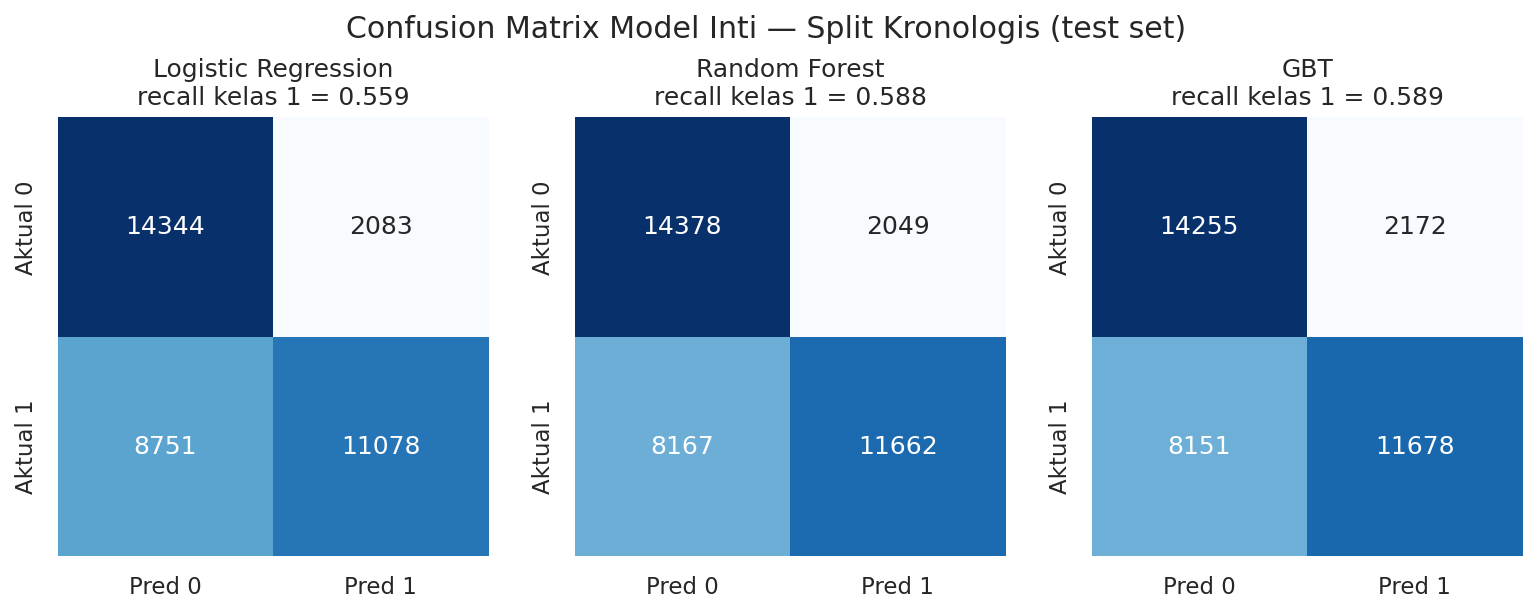

In [35]:
# Confusion matrix model inti Spark MLlib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
sns.set_theme(style="whitegrid")

inti_spark = [h for h in hasil_utama if h["peran"] == "inti" and h["framework"] == "Spark MLlib"]
fig, axes = plt.subplots(1, len(inti_spark), figsize=(4.2 * len(inti_spark), 3.8))
for ax, h in zip(np.atleast_1d(axes), inti_spark):
    cm = np.array([[h["TN"], h["FP"]], [h["FN"], h["TP"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Aktual 0", "Aktual 1"])
    ax.set_title(f"{h['model']}\nrecall kelas 1 = {h['recall_pos']:.3f}")
fig.suptitle("Confusion Matrix Model Inti — Split Kronologis (test set)", y=1.06)
fig.savefig(ANALYTICS + "/gambar_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.close("all")
display(Image(ANALYTICS + "/gambar_confusion_matrix.png"))

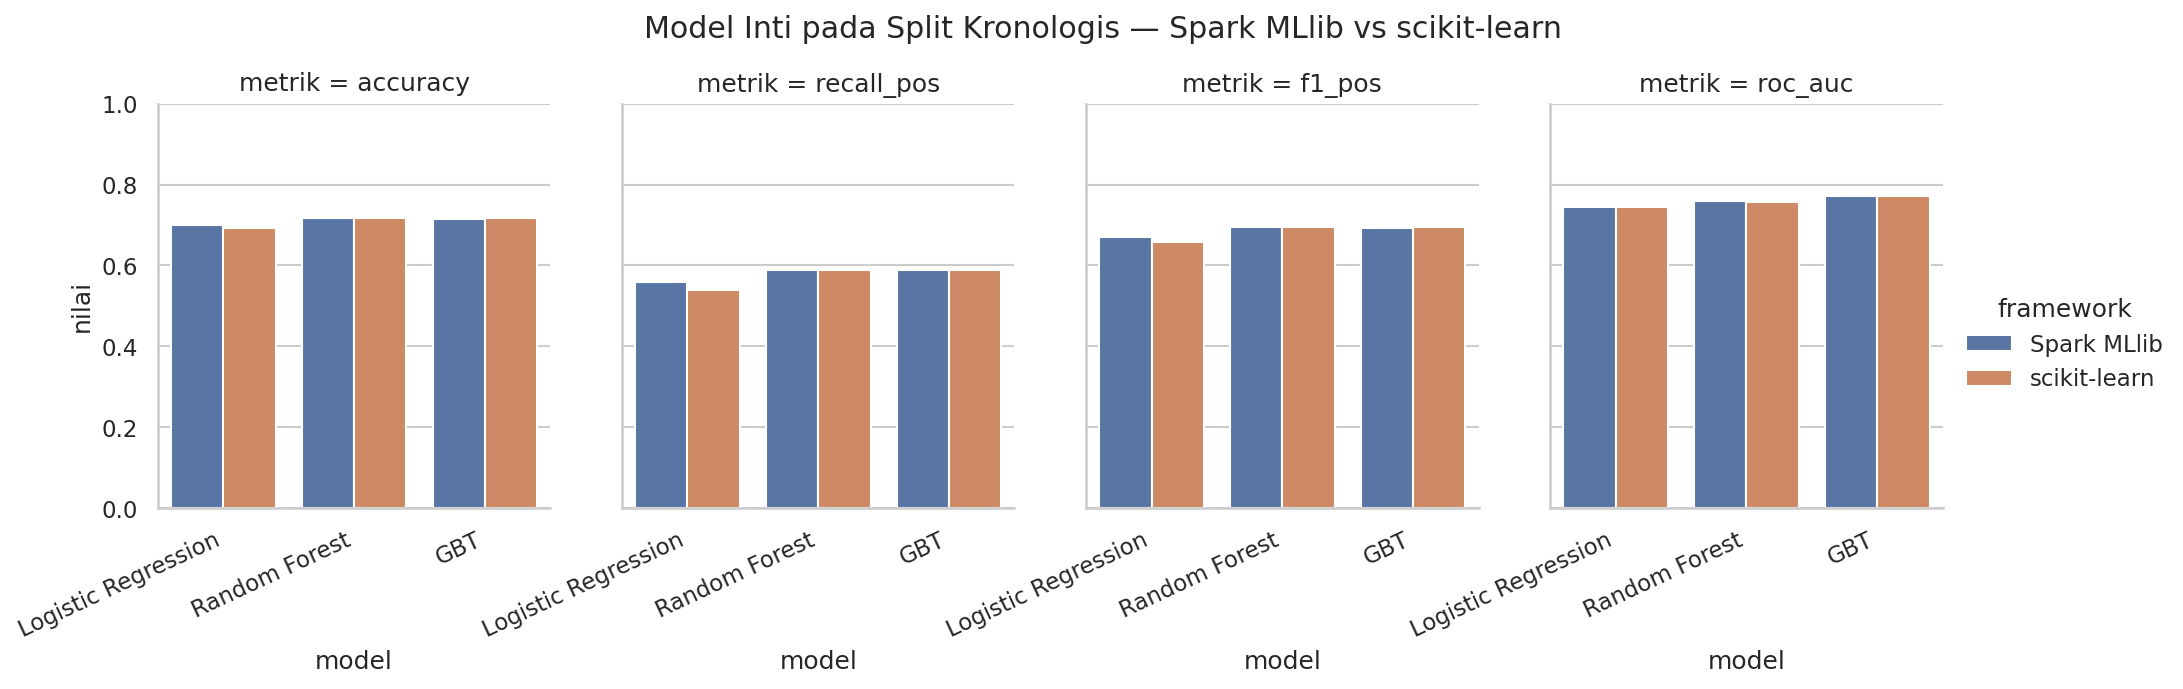

In [36]:
# Perbandingan metrik kelas positif antar model inti
plot_df = df_main[df_main.peran == "inti"].melt(
    id_vars=["model", "framework"],
    value_vars=["accuracy", "recall_pos", "f1_pos", "roc_auc"],
    var_name="metrik", value_name="nilai",
)
g = sns.catplot(data=plot_df, x="model", y="nilai", hue="framework",
                col="metrik", kind="bar", height=3.8, aspect=0.85)
g.set_xticklabels(rotation=25, ha="right"); g.set(ylim=(0, 1))
g.figure.suptitle("Model Inti pada Split Kronologis — Spark MLlib vs scikit-learn", y=1.05)
g.savefig(ANALYTICS + "/gambar_perbandingan_metrik.png", dpi=150, bbox_inches="tight")
plt.close("all")
display(Image(ANALYTICS + "/gambar_perbandingan_metrik.png"))

### Baseline Model

In [37]:
bl_rule = (
    train_main.groupBy("shipping_mode")
    .agg(F.avg(TARGET).alias("late_rate_train"), F.count("*").alias("n_train"))
    .withColumn("prediksi", (F.col("late_rate_train") > 0.5).cast("int"))
)
bl_rule.orderBy(F.desc("late_rate_train")).show(truncate=False)

bl_pred = test_main.join(bl_rule.select("shipping_mode", "prediksi"), on="shipping_mode", how="left") \
                   .withColumn("prediksi", F.coalesce(F.col("prediksi"), F.lit(0)))

tp = bl_pred.filter((F.col(TARGET) == 1) & (F.col("prediksi") == 1)).count()
tn = bl_pred.filter((F.col(TARGET) == 0) & (F.col("prediksi") == 0)).count()
fp = bl_pred.filter((F.col(TARGET) == 0) & (F.col("prediksi") == 1)).count()
fn = bl_pred.filter((F.col(TARGET) == 1) & (F.col("prediksi") == 0)).count()
acc, pre, rec, f1, spec = metrik_dari_cm(tp, fp, fn, tn)

hasil_baseline = {
    "model": "Baseline lookup Shipping Mode", "peran": "baseline", "framework": "—",
    "split": "chronological_test", "accuracy": acc,
    "precision_weighted": None, "recall_weighted": None, "f1_weighted": None,
    "precision_pos": pre, "recall_pos": rec, "f1_pos": f1, "specificity": spec,
    "roc_auc": None, "auc_pr": None, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    "fit_time_s": 0.0, "prep_time_s": None, "convert_time_s": None, "threshold": 0.5,
}
hasil_utama.append(hasil_baseline)
df_main = pd.DataFrame(hasil_utama)

# Penyetelan ambang memakai objek model Spark, jadi pemilihan dibatasi ke baris Spark MLlib
terbaik = (df_main[(df_main.peran == "inti") & (df_main.framework == "Spark MLlib")]
           .sort_values("roc_auc", ascending=False).iloc[0])
print(f"Baseline        : accuracy {acc:.4f} | recall kelas 1 {rec:.4f} | FN {fn} | FP {fp}")
print(f"Model terbaik   : {terbaik['model']} ({terbaik['framework']}) "
      f"accuracy {terbaik['accuracy']:.4f} | recall kelas 1 {terbaik['recall_pos']:.4f} "
      f"| FN {int(terbaik['FN'])} | FP {int(terbaik['FP'])}")
print(f"Selisih accuracy: {terbaik['accuracy'] - acc:+.4f} "
      f"({(terbaik['accuracy'] - acc)*100:+.2f} poin persentase)")

+--------------+-------------------+-------+--------+
|shipping_mode |late_rate_train    |n_train|prediksi|
+--------------+-------------------+-------+--------+
|First Class   |0.956009186016841  |19595  |1       |
|Second Class  |0.7695431472081218 |24625  |1       |
|Same Day      |0.4384876679958647 |6771   |0       |
|Standard Class|0.38149866404349503|75227  |0       |
+--------------+-------------------+-------+--------+

Baseline        : accuracy 0.6926 | recall kelas 1 0.5384 | FN 9154 | FP 1992
Model terbaik   : GBT (Spark MLlib) accuracy 0.7153 | recall kelas 1 0.5889 | FN 8151 | FP 2172
Selisih accuracy: +0.0227 (+2.27 poin persentase)


### Penyelarasan Ambang Batas Keputusan (Threshold Tuning)

In [38]:
RASIO_FN_FP = 3.0
MODEL_AMBANG = terbaik["model"]
model_th = fitted_spark[MODEL_AMBANG]

def prob_pandas(model, data):
    return (model.transform(data)
            .select(F.col(TARGET).alias("y"), vector_to_array("probability")[1].alias("p"))
            .toPandas())

pv = prob_pandas(model_th, val_v)

baris = []
for th in np.arange(0.02, 0.991, 0.01):
    yp = (pv.p.values >= th).astype(int)
    tp_ = int(((pv.y == 1) & (yp == 1)).sum()); fp_ = int(((pv.y == 0) & (yp == 1)).sum())
    fn_ = int(((pv.y == 1) & (yp == 0)).sum()); tn_ = int(((pv.y == 0) & (yp == 0)).sum())
    a, p_, r_, f_, s_ = metrik_dari_cm(tp_, fp_, fn_, tn_)
    baris.append({"threshold": round(float(th), 2), "accuracy": a, "precision_pos": p_,
                  "recall_pos": r_, "f1_pos": f_, "specificity": s_,
                  "youden": r_ + s_ - 1, "balanced_accuracy": (r_ + s_) / 2,
                  "TP": tp_, "FP": fp_, "FN": fn_, "TN": tn_,
                  "biaya": RASIO_FN_FP * fn_ + fp_})

th_val = pd.DataFrame(baris)

# Pembanding: F1 kelas positif bila SELURUH order diprediksi terlambat
pi = pv.y.mean()
F1_TRIVIAL = 2 * pi / (pi + 1)

KRITERIA = {
    "F1 kelas positif maks":   float(th_val.loc[th_val.f1_pos.idxmax(), "threshold"]),
    "Youden J maks":           float(th_val.loc[th_val.youden.idxmax(), "threshold"]),
    "Balanced accuracy maks":  float(th_val.loc[th_val.balanced_accuracy.idxmax(), "threshold"]),
    "Accuracy maks":           float(th_val.loc[th_val.accuracy.idxmax(), "threshold"]),
    "Biaya minimum":           float(th_val.loc[th_val.biaya.idxmin(), "threshold"]),
}

print(f"Model untuk penyetelan   : {MODEL_AMBANG}")
print(f"Proporsi kelas 1 (valid) : {pi:.4f}")
print(f"F1 klasifikator trivial  : {F1_TRIVIAL:.4f}  <- pembanding wajib untuk kriteria F1\n")

print("{:<26}{:>8}{:>10}{:>10}{:>10}{:>10}{:>9}".format(
    "Kriteria", "ambang", "accuracy", "recall+", "prec+", "spec", "J"))
for nm, th in KRITERIA.items():
    r = th_val[th_val.threshold == th].iloc[0]
    print("{:<26}{:>8.2f}{:>10.4f}{:>10.4f}{:>10.4f}{:>10.4f}{:>9.4f}".format(
        nm, th, r.accuracy, r.recall_pos, r.precision_pos, r.specificity, r.youden))

r_f1 = th_val[th_val.threshold == KRITERIA["F1 kelas positif maks"]].iloc[0]
print(f"\nF1 pada ambang 'terbaik' menurut F1 : {r_f1.f1_pos:.4f}")
print(f"Selisih terhadap klasifikator trivial: {r_f1.f1_pos - F1_TRIVIAL:+.4f}")

Model untuk penyetelan   : GBT
Proporsi kelas 1 (valid) : 0.5429
F1 klasifikator trivial  : 0.7038  <- pembanding wajib untuk kriteria F1

Kriteria                    ambang  accuracy   recall+     prec+      spec        J
F1 kelas positif maks         0.31    0.5783    0.9836    0.5640    0.0970   0.0806
Youden J maks                 0.54    0.7051    0.5648    0.8395    0.8717   0.4365
Balanced accuracy maks        0.54    0.7051    0.5648    0.8395    0.8717   0.4365
Accuracy maks                 0.48    0.7060    0.5839    0.8231    0.8510   0.4348
Biaya minimum                 0.06    0.5690    1.0000    0.5574    0.0570   0.0570

F1 pada ambang 'terbaik' menurut F1 : 0.7169
Selisih terhadap klasifikator trivial: +0.0132


In [39]:
TH_J   = KRITERIA["Youden J maks"]
TH_F1  = KRITERIA["F1 kelas positif maks"]
TH_COST = KRITERIA["Biaya minimum"]

pt = prob_pandas(model_th, test_v)

def eval_threshold(th, label):
    yp = (pt.p.values >= th).astype(int)
    tp_ = int(((pt.y == 1) & (yp == 1)).sum()); fp_ = int(((pt.y == 0) & (yp == 1)).sum())
    fn_ = int(((pt.y == 1) & (yp == 0)).sum()); tn_ = int(((pt.y == 0) & (yp == 0)).sum())
    a, p_, r_, f_, s_ = metrik_dari_cm(tp_, fp_, fn_, tn_)
    return {"model": f"{MODEL_AMBANG} @ ambang {th:.2f}", "peran": "varian ambang",
            "framework": "Spark MLlib", "split": "chronological_test", "accuracy": a,
            "precision_weighted": None, "recall_weighted": None, "f1_weighted": None,
            "precision_pos": p_, "recall_pos": r_, "f1_pos": f_, "specificity": s_,
            "youden": r_ + s_ - 1,
            "roc_auc": float(terbaik["roc_auc"]), "auc_pr": float(terbaik["auc_pr"]),
            "TP": tp_, "FP": fp_, "FN": fn_, "TN": tn_,
            "fit_time_s": None, "prep_time_s": None, "convert_time_s": None,
            "threshold": th, "kriteria_ambang": label}

varian = [eval_threshold(0.50, "baku"),
          eval_threshold(TH_J, "Youden J maks (validation)"),
          eval_threshold(TH_F1, "F1 maks (validation)"),
          eval_threshold(TH_COST, "biaya minimum (validation)")]
hasil_utama += varian
df_main = pd.DataFrame(hasil_utama)

print("=== HASIL PADA TEST SET setelah ambang ditetapkan dari validation ===\n")
print(pd.DataFrame(varian)[["kriteria_ambang", "threshold", "accuracy", "precision_pos",
                            "recall_pos", "f1_pos", "specificity", "youden", "FN", "FP"]]
      .round(4).to_string(index=False))

=== HASIL PADA TEST SET setelah ambang ditetapkan dari validation ===

           kriteria_ambang  threshold  accuracy  precision_pos  recall_pos  f1_pos  specificity  youden   FN    FP
                      baku       0.50    0.7153         0.8432      0.5889  0.6935       0.8678  0.4567 8151  2172
Youden J maks (validation)       0.54    0.7149         0.8453      0.5861  0.6922       0.8705  0.4566 8208  2127
      F1 maks (validation)       0.31    0.5798         0.5667      0.9849  0.7194       0.0909  0.0758  300 14933
biaya minimum (validation)       0.06    0.5721         0.5611      1.0000  0.7188       0.0556  0.0556    0 15513


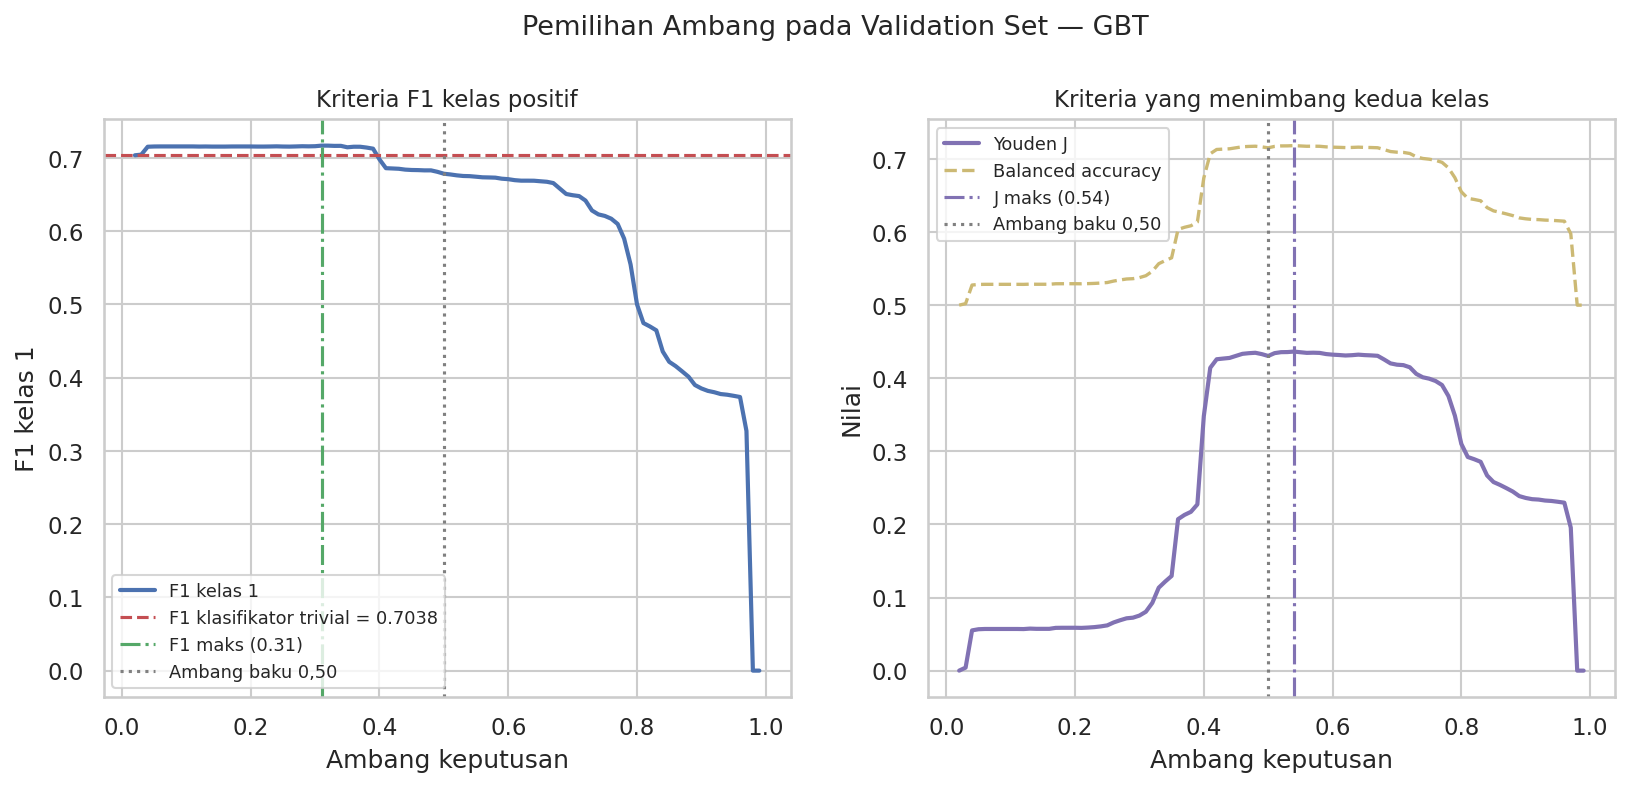

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(th_val.threshold, th_val.f1_pos, color="#4C72B0", lw=2, label="F1 kelas 1")
ax1.axhline(F1_TRIVIAL, color="#C44E52", ls="--", lw=1.5,
            label=f"F1 klasifikator trivial = {F1_TRIVIAL:.4f}")
ax1.axvline(TH_F1, color="#55A868", ls="-.", lw=1.5, label=f"F1 maks ({TH_F1:.2f})")
ax1.axvline(0.5, color="grey", ls=":", lw=1.5, label="Ambang baku 0,50")
ax1.set_xlabel("Ambang keputusan"); ax1.set_ylabel("F1 kelas 1")
ax1.set_title("Kriteria F1 kelas positif", fontsize=11); ax1.legend(fontsize=8.5)

ax2.plot(th_val.threshold, th_val.youden, color="#8172B3", lw=2, label="Youden J")
ax2.plot(th_val.threshold, th_val.balanced_accuracy, color="#CCB974", lw=1.6, ls="--",
         label="Balanced accuracy")
ax2.axvline(TH_J, color="#8172B3", ls="-.", lw=1.5, label=f"J maks ({TH_J:.2f})")
ax2.axvline(0.5, color="grey", ls=":", lw=1.5, label="Ambang baku 0,50")
ax2.set_xlabel("Ambang keputusan"); ax2.set_ylabel("Nilai")
ax2.set_title("Kriteria yang menimbang kedua kelas", fontsize=11); ax2.legend(fontsize=8.5)

fig.suptitle(f"Pemilihan Ambang pada Validation Set — {MODEL_AMBANG}", fontsize=13, y=1.02)
fig.savefig(ANALYTICS + "/gambar_ambang_kriteria.png", dpi=150, bbox_inches="tight")
plt.close("all")
display(Image(ANALYTICS + "/gambar_ambang_kriteria.png"))

### Analisis Prediksi Terhadap Metode Pengiriman

In [41]:
pred_detail = (
    model_th.transform(test_v)
    .select("shipping_mode", "order_region", "order_country", "category_name", "order_ts",
            F.col(TARGET).alias("aktual"),
            F.col("prediction").cast("int").alias("pred"),
            F.round(vector_to_array("probability")[1], 6).alias("prob"))
    .toPandas()
)

print("=== Distribusi probabilitas per shipping_mode (test set) ===")
ringkas = (pred_detail.groupby("shipping_mode")
           .agg(n=("aktual", "size"), late_aktual=("aktual", "mean"),
                prob_min=("prob", "min"), prob_q25=("prob", lambda s: s.quantile(.25)),
                prob_median=("prob", "median"), prob_q75=("prob", lambda s: s.quantile(.75)),
                prob_max=("prob", "max"), rate_prediksi_1=("pred", "mean"))
           .round(4).sort_values("late_aktual"))
print(ringkas.to_string())
ringkas.to_csv(ANALYTICS + "/prob_per_shipping_mode.csv")

print("\n=== Asal false negative (ambang 0,50) ===")
fn_df = pred_detail[(pred_detail.aktual == 1) & (pred_detail.pred == 0)]
komposisi = (fn_df.groupby("shipping_mode").size().rename("jumlah_FN").to_frame())
komposisi["persen_dari_total_FN"] = (100 * komposisi.jumlah_FN / len(fn_df)).round(2)
print(komposisi.sort_values("jumlah_FN", ascending=False).to_string())
print(f"\nTotal false negative: {len(fn_df)}")
komposisi.to_csv(ANALYTICS + "/komposisi_false_negative.csv")

=== Distribusi probabilitas per shipping_mode (test set) ===
                    n  late_aktual  prob_min  prob_q25  prob_median  prob_q75  prob_max  rate_prediksi_1
shipping_mode                                                                                           
Standard Class  21630       0.3776    0.1157    0.3446       0.3950    0.4038    0.8793           0.0131
Same Day         1959       0.5038    0.0191    0.0350       0.5248    0.9639    0.9727           0.5048
Second Class     7066       0.7615    0.3896    0.7257       0.7918    0.7988    0.9112           0.9939
First Class      5601       0.9452    0.2231    0.9081       0.9785    0.9785    0.9785           0.9918

=== Asal false negative (ambang 0,50) ===
                jumlah_FN  persen_dari_total_FN
shipping_mode                                  
Standard Class       8046                 98.71
Same Day               39                  0.48
First Class            33                  0.40
Second Class           33 

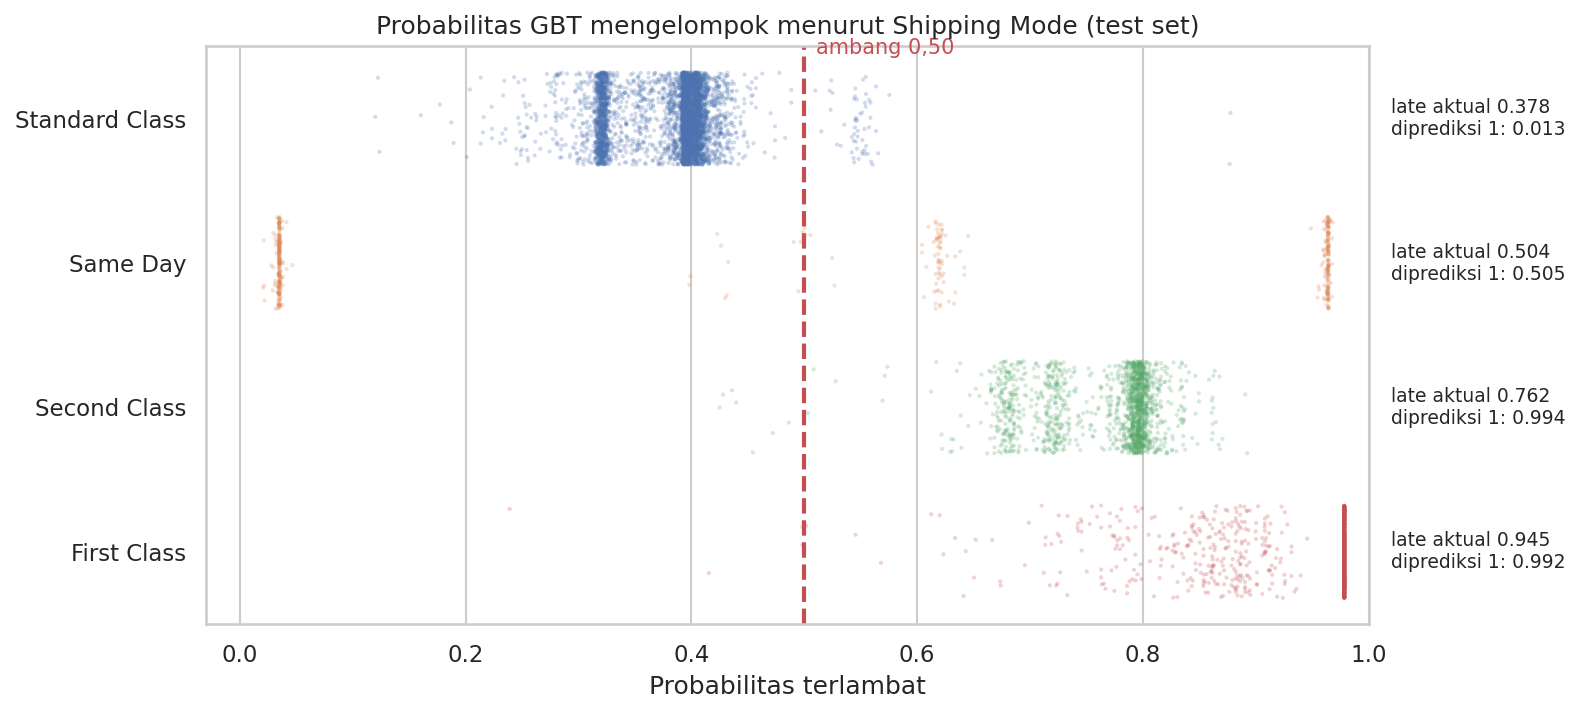

In [42]:
fig, ax = plt.subplots(figsize=(10, 5))
urut = ringkas.index.tolist()
sampel = pred_detail.sample(min(8000, len(pred_detail)), random_state=SEED)
sns.stripplot(data=sampel, x="prob", y="shipping_mode", order=urut, hue="shipping_mode",
              hue_order=urut, size=2, alpha=0.25, jitter=0.32, legend=False, ax=ax)
ax.axvline(0.5, color="#C44E52", ls="--", lw=2)
ax.text(0.51, -0.45, "ambang 0,50", color="#C44E52", fontsize=10)
for i, m in enumerate(urut):
    s = pred_detail[pred_detail.shipping_mode == m]
    ax.text(1.02, i, f"late aktual {s.aktual.mean():.3f}\ndiprediksi 1: {s.pred.mean():.3f}",
            va="center", fontsize=9)
ax.set_xlim(-0.03, 1.0); ax.set_xlabel("Probabilitas terlambat"); ax.set_ylabel("")
ax.set_title(f"Probabilitas {MODEL_AMBANG} mengelompok menurut Shipping Mode (test set)", fontsize=12)
fig.savefig(ANALYTICS + "/gambar_prob_per_mode.png", dpi=150, bbox_inches="tight")
plt.close("all")
display(Image(ANALYTICS + "/gambar_prob_per_mode.png"))

### Feature Importance (Random Forest)

20 fitur teratas:
                           fitur  importance        kelompok
shipping_mode_ohe_Standard Class     0.32289   shipping_mode
                      sched_days     0.23572      sched_days
   shipping_mode_ohe_First Class     0.20839   shipping_mode
  shipping_mode_ohe_Second Class     0.08855   shipping_mode
                      order_hour     0.04797     fitur waktu
      shipping_mode_ohe_Same Day     0.04517   shipping_mode
       payment_type_ohe_TRANSFER     0.01133    payment_type
          payment_type_ohe_DEBIT     0.00328    payment_type
                 order_dayofweek     0.00232     fitur waktu
        payment_type_ohe_PAYMENT     0.00218    payment_type
                     order_month     0.00204     fitur waktu
                   discount_rate     0.00163 nilai transaksi
                 discount_amount     0.00149 nilai transaksi
                      line_total     0.00119 nilai transaksi
                           sales     0.00112 nilai transaksi
      

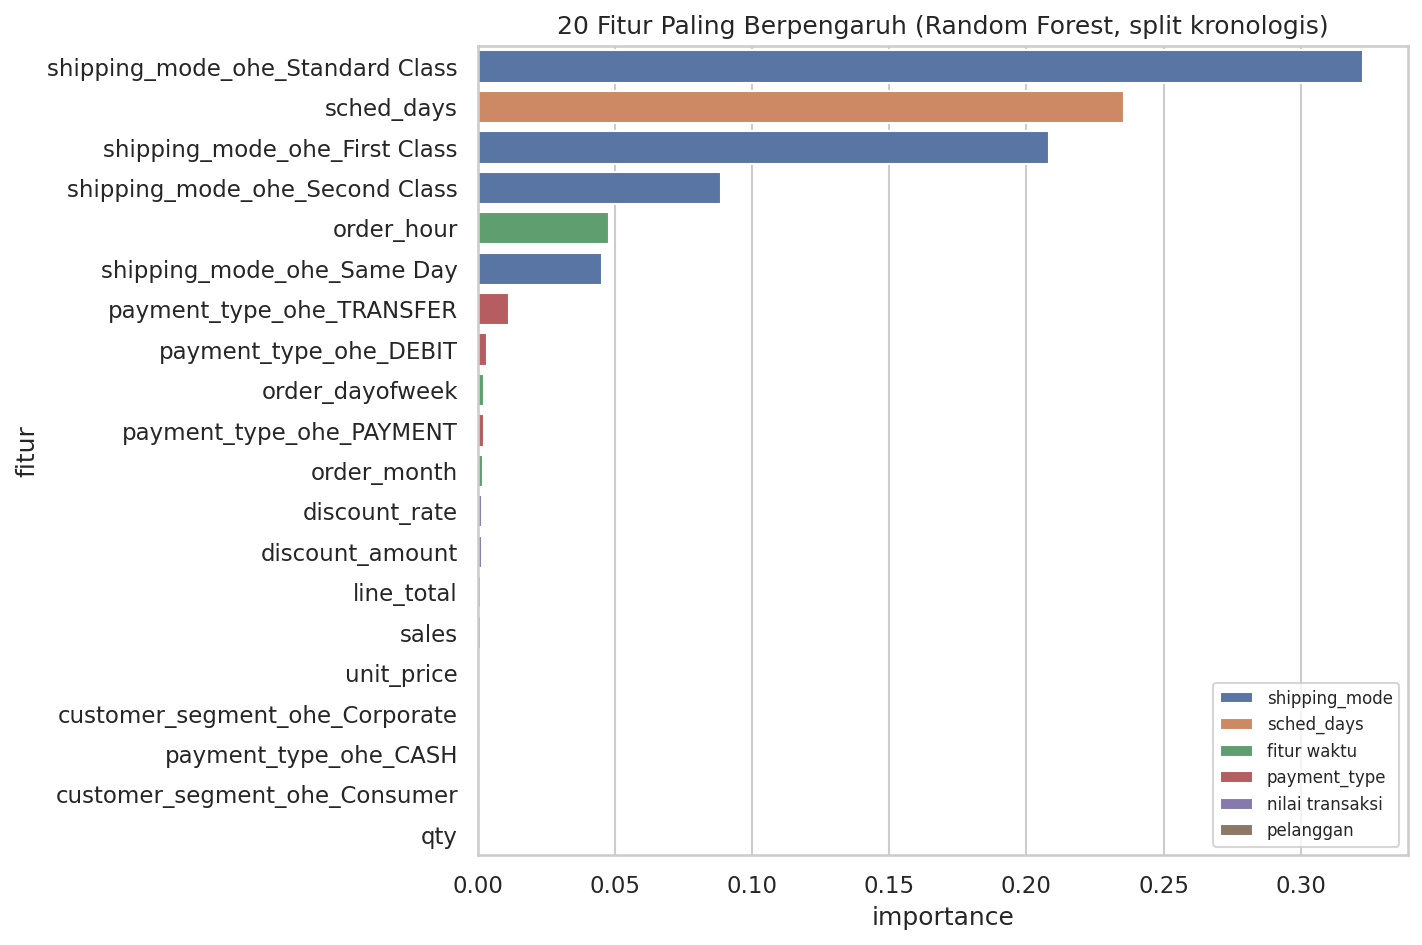

In [43]:
rf = fitted_spark["Random Forest"]
meta = train_v.schema["features_raw"].metadata["ml_attr"]["attrs"]
nama_fitur = {a["idx"]: a["name"] for jenis in meta for a in meta[jenis]}

imp = rf.featureImportances.toArray()

def kelompok(f):
    if f.startswith("shipping_mode"): return "shipping_mode"
    if f.startswith("payment_type"):  return "payment_type"
    if f == "sched_days":             return "sched_days"
    if f.startswith("order_") or f == "is_weekend": return "fitur waktu"
    if f.startswith(("order_region", "order_country", "market")): return "geografis"
    if f.startswith(("category_name", "department_name", "price_bucket")): return "produk"
    if f.startswith("customer_segment"): return "pelanggan"
    return "nilai transaksi"

imp_df = pd.DataFrame({
    "fitur": [nama_fitur.get(i, f"f{i}") for i in range(len(imp))],
    "importance": imp,
})
imp_df["kelompok"] = imp_df.fitur.map(kelompok)
imp_df = imp_df.sort_values("importance", ascending=False).reset_index(drop=True)

print("20 fitur teratas:")
print(imp_df.head(20).round(5).to_string(index=False))
print("\nAgregasi per kelompok (seluruh fitur):")
grp = imp_df.groupby("kelompok").importance.sum().sort_values(ascending=False)
print(grp.round(4).to_string())
print(f"\nshipping_mode + sched_days = {grp.get('shipping_mode',0)+grp.get('sched_days',0):.4f}")
print("Catatan: keduanya redundan (lihat 5.3), sehingga angka ini mewakili SATU variabel.")

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=imp_df.head(20), y="fitur", x="importance", hue="kelompok", dodge=False, ax=ax)
ax.set_title("20 Fitur Paling Berpengaruh (Random Forest, split kronologis)")
ax.legend(fontsize=8, loc="lower right")
fig.savefig(ANALYTICS + "/gambar_feature_importance.png", dpi=150, bbox_inches="tight")
plt.close("all")
display(Image(ANALYTICS + "/gambar_feature_importance.png"))

In [44]:
# Cross-check: importance dari GBT, untuk memastikan temuan tidak khas satu algoritma
gbt_imp = fitted_spark["GBT"].featureImportances.toArray()
cmp_df = pd.DataFrame({
    "fitur": [nama_fitur.get(i, f"f{i}") for i in range(len(gbt_imp))],
    "importance_gbt": gbt_imp,
}).merge(imp_df[["fitur", "importance", "kelompok"]].rename(columns={"importance": "importance_rf"}),
         on="fitur", how="left")

agg = (cmp_df.groupby("kelompok")[["importance_rf", "importance_gbt"]].sum()
       .sort_values("importance_rf", ascending=False).round(4))
print("Agregasi importance per kelompok: Random Forest vs GBT")
print(agg.to_string())
cmp_df.round(6).to_csv(ANALYTICS + "/feature_importance_rf_vs_gbt.csv", index=False)

Agregasi importance per kelompok: Random Forest vs GBT
                 importance_rf  importance_gbt
kelompok                                      
shipping_mode           0.6650          0.5380
sched_days              0.2357          0.0244
fitur waktu             0.0683          0.3007
payment_type            0.0175          0.0783
nilai transaksi         0.0070          0.0186
produk                  0.0040          0.0082
pelanggan               0.0020          0.0296
geografis               0.0005          0.0021


### Uji Redundansi Fitur (Ablation Study)

In [45]:
def latih_tanpa(buang_num=None, buang_cat=None, label=""):
    nf = [c for c in NUM_FEATURES if c != buang_num]
    cf = [c for c in CAT_ALL if c != buang_cat]
    idx = [c + "_idx" for c in cf]; ohe = [c + "_ohe" for c in cf]
    stages = ([StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in cf]
              + [OneHotEncoder(inputCols=idx, outputCols=ohe, handleInvalid="keep"),
                 VectorAssembler(inputCols=ohe + nf, outputCol="features_raw", handleInvalid="keep"),
                 StandardScaler(inputCol="features_raw", outputCol="features",
                                withMean=False, withStd=True)])
    fm = Pipeline(stages=stages).fit(train_main)
    tr = fm.transform(train_main).select("features", TARGET)
    te = fm.transform(test_main).select("features", TARGET)
    m = RandomForestClassifier(featuresCol="features", labelCol=TARGET,
                               **MODEL_PARAMS["Random Forest"]).fit(tr)
    pred = m.transform(te).cache()
    tp_ = pred.filter((F.col(TARGET)==1)&(F.col("prediction")==1)).count()
    tn_ = pred.filter((F.col(TARGET)==0)&(F.col("prediction")==0)).count()
    fp_ = pred.filter((F.col(TARGET)==0)&(F.col("prediction")==1)).count()
    fn_ = pred.filter((F.col(TARGET)==1)&(F.col("prediction")==0)).count()
    a, p_, r_, f_, s_ = metrik_dari_cm(tp_, fp_, fn_, tn_)
    auc_ = ev_auc.evaluate(pred); pred.unpersist()
    return {"varian": label, "n_fitur_num": len(nf), "n_fitur_cat": len(cf),
            "accuracy": round(a, 4), "recall_pos": round(r_, 4),
            "f1_pos": round(f_, 4), "roc_auc": round(auc_, 4)}

rf_full = df_main[(df_main.model == "Random Forest") & (df_main.framework == "Spark MLlib")
                  & (df_main.split == "chronological_test")].iloc[0]
uji_red = [
    {"varian": "Lengkap", "n_fitur_num": len(NUM_FEATURES), "n_fitur_cat": len(CAT_ALL),
     "accuracy": round(float(rf_full.accuracy), 4), "recall_pos": round(float(rf_full.recall_pos), 4),
     "f1_pos": round(float(rf_full.f1_pos), 4), "roc_auc": round(float(rf_full.roc_auc), 4)},
    latih_tanpa(buang_num="sched_days", label="Tanpa sched_days"),
    latih_tanpa(buang_cat="shipping_mode", label="Tanpa shipping_mode"),
]
red_df = pd.DataFrame(uji_red)
red_df.to_csv(ANALYTICS + "/uji_redundansi_fitur.csv", index=False)
print("Random Forest pada test set kronologis:\n")
print(red_df.to_string(index=False))
print("\nSelisih accuracy terhadap model lengkap:")
for r in uji_red[1:]:
    print(f"  {r['varian']:<22}{r['accuracy'] - uji_red[0]['accuracy']:+.4f}")

Random Forest pada test set kronologis:

             varian  n_fitur_num  n_fitur_cat  accuracy  recall_pos  f1_pos  roc_auc
            Lengkap           12            9    0.7182      0.5881  0.6954   0.7596
   Tanpa sched_days           11            9    0.7177      0.5895  0.6955   0.7566
Tanpa shipping_mode           12            8    0.6895      0.5974  0.6779   0.7357

Selisih accuracy terhadap model lengkap:
  Tanpa sched_days      -0.0005
  Tanpa shipping_mode   -0.0287


### Analisis Performa Per Segmen

In [46]:
def performa_segmen(kolom):
    g = pred_detail.copy()
    g["benar"] = (g.aktual == g.pred).astype(int)
    out = (g.groupby(kolom)
             .apply(lambda s: pd.Series({
                 "n": len(s),
                 "late_aktual": s.aktual.mean(),
                 "rate_prediksi_1": s.pred.mean(),
                 "accuracy": s.benar.mean(),
                 "recall_pos": ((s.aktual == 1) & (s.pred == 1)).sum() / max((s.aktual == 1).sum(), 1),
                 "FN": int(((s.aktual == 1) & (s.pred == 0)).sum()),
                 "FP": int(((s.aktual == 0) & (s.pred == 1)).sum()),
             }), include_groups=False)
             .round(4).sort_values("n", ascending=False))
    return out

seg_mode = performa_segmen("shipping_mode")
print("=== Per Shipping Mode ===");  print(seg_mode.to_string())
seg_mode.to_csv(ANALYTICS + "/performa_per_shipping_mode.csv")

seg_reg = performa_segmen("order_region").head(12)
print("\n=== Per Order Region (12 terbesar) ===");  print(seg_reg.to_string())
performa_segmen("order_region").to_csv(ANALYTICS + "/performa_per_region.csv")

pred_detail["bulan"] = pd.to_datetime(pred_detail.order_ts).dt.to_period("M").astype(str)
seg_bulan = performa_segmen("bulan").sort_index()
print("\n=== Per bulan pada periode test ===");  print(seg_bulan.to_string())
seg_bulan.to_csv(ANALYTICS + "/performa_per_bulan.csv")

=== Per Shipping Mode ===
                      n  late_aktual  rate_prediksi_1  accuracy  recall_pos      FN      FP
shipping_mode                                                                              
Standard Class  21630.0       0.3776           0.0131    0.6205      0.0148  8046.0   162.0
Second Class     7066.0       0.7615           0.9939    0.7583      0.9939    33.0  1675.0
First Class      5601.0       0.9452           0.9918    0.9416      0.9938    33.0   294.0
Same Day         1959.0       0.5038           0.5048    0.9592      0.9605    39.0    41.0

=== Per Order Region (12 terbesar) ===
                       n  late_aktual  rate_prediksi_1  accuracy  recall_pos      FN     FP
order_region                                                                               
Western Europe   12351.0       0.5539           0.3904    0.7238      0.6031  2715.0  696.0
Central America   5348.0       0.5486           0.3534    0.7053      0.5535  1310.0  266.0
Northern Europ

### Analisis Sensitivitas: Random Split vs Chronological Split

In [47]:
tr_r, te_r = feat_df.randomSplit([0.8, 0.2], seed=SEED)
fm_r = Pipeline(stages=feature_stages).fit(tr_r)
tr_rv = fm_r.transform(tr_r).select("features", TARGET).cache()
te_rv = fm_r.transform(te_r).select("features", TARGET).cache()

hasil_acak = []
for nama in MODEL_INTI:
    algo = spark_algos[nama].copy()
    m = algo.fit(tr_rv)
    pred = m.transform(te_rv).cache()
    tp_ = pred.filter((F.col(TARGET)==1)&(F.col("prediction")==1)).count()
    tn_ = pred.filter((F.col(TARGET)==0)&(F.col("prediction")==0)).count()
    fp_ = pred.filter((F.col(TARGET)==0)&(F.col("prediction")==1)).count()
    fn_ = pred.filter((F.col(TARGET)==1)&(F.col("prediction")==0)).count()
    a, p_, r_, f_, s_ = metrik_dari_cm(tp_, fp_, fn_, tn_)
    hasil_acak.append({"model": nama, "peran": "sensitivitas", "framework": "Spark MLlib",
                       "split": "random_test", "accuracy": a, "precision_weighted": None,
                       "recall_weighted": None, "f1_weighted": None, "precision_pos": p_,
                       "recall_pos": r_, "f1_pos": f_, "specificity": s_,
                       "roc_auc": ev_auc.evaluate(pred), "auc_pr": ev_pr.evaluate(pred),
                       "TP": tp_, "FP": fp_, "FN": fn_, "TN": tn_, "fit_time_s": None,
                       "prep_time_s": None, "convert_time_s": None, "threshold": 0.5})
    pred.unpersist()

hasil_utama += hasil_acak
df_main = pd.DataFrame(hasil_utama)

bandingkan = (df_main[df_main.split.isin(["chronological_test", "random_test"])
                      & df_main.model.isin(MODEL_INTI) & (df_main.framework == "Spark MLlib")]
              .pivot_table(index="model", columns="split",
                           values=["accuracy", "f1_pos", "roc_auc"]).round(4))
print("=== Kronologis vs acak (model inti, Spark MLlib) ===")
print(bandingkan.to_string())

=== Kronologis vs acak (model inti, Spark MLlib) ===
                              accuracy                         f1_pos                        roc_auc            
split               chronological_test random_test chronological_test random_test chronological_test random_test
model                                                                                                           
GBT                             0.7153      0.7221             0.6935      0.7021             0.7714      0.7873
Logistic Regression             0.7012      0.7084             0.6716      0.6857             0.7440      0.7461
Random Forest                   0.7182      0.7205             0.6954      0.6985             0.7596      0.7569


### Graph Analytics: Relasi Lokasi & Negara Tujuan

In [48]:
flow = (
    df.filter(F.col("order_country").isNotNull())
      .select(
          F.concat(F.lit("CUST::"), F.coalesce(F.col("customer_state"), F.lit("UNKNOWN"))).alias("src"),
          F.concat(F.lit("DEST::"), F.col("order_country")).alias("dst"),
          F.col(TARGET).cast("int").alias("late"),
          F.col("sales"),
      )
)

AMBANG_EDGE_G1 = 30
edges1_raw = flow.groupBy("src", "dst").agg(
    F.count("*").alias("weight"),
    F.round(F.avg("late"), 4).alias("late_rate"),
    F.round(F.sum("sales"), 2).alias("total_sales"),
)
edges1 = edges1_raw.filter(F.col("weight") >= AMBANG_EDGE_G1).cache()

vertices1 = (
    edges1.select(F.col("src").alias("id")).union(edges1.select(F.col("dst").alias("id"))).distinct()
    .withColumn("tipe", F.split(F.col("id"), "::").getItem(0))
    .withColumn("nama", F.split(F.col("id"), "::").getItem(1))
    .cache()
)

print("Sebelum penyaringan :", edges1_raw.count(), "edge")
print("Sesudah penyaringan :", edges1.count(), "edge |", vertices1.count(), "node")
print("\nDistribusi bobot edge:")
edges1.select("weight").describe().show()
print("Node per tipe:")
vertices1.groupBy("tipe").count().show()

Sebelum penyaringan : 3139 edge
Sesudah penyaringan : 751 edge | 142 node

Distribusi bobot edge:
+-------+------------------+
|summary|            weight|
+-------+------------------+
|  count|               751|
|   mean|214.27430093209054|
| stddev|  570.411252219552|
|    min|                30|
|    max|              9398|
+-------+------------------+

Node per tipe:
+----+-----+
|tipe|count|
+----+-----+
|DEST|  106|
|CUST|   36|
+----+-----+



In [49]:
GRAPHFRAMES_OK = True
try:
    from graphframes import GraphFrame
    g1 = GraphFrame(vertices1, edges1)
    print("GraphFrames aktif.")
except Exception as exc:
    GRAPHFRAMES_OK = False
    print("GraphFrames tidak tersedia:", exc)

GraphFrames aktif.


In [50]:
graph_summary = []

if GRAPHFRAMES_OK:
    print("=== Degree ===")
    g1.degrees.orderBy(F.desc("degree")).show(10, truncate=False)

    print("=== In-degree (node tujuan) ===")
    g1.inDegrees.orderBy(F.desc("inDegree")).show(10, truncate=False)

    print("=== PageRank ===")
    pr1 = g1.pageRank(resetProbability=0.15, maxIter=10)
    pr1_v = pr1.vertices.select("id", "tipe", "nama", F.round("pagerank", 5).alias("pagerank"))
    pr1_v.orderBy(F.desc("pagerank")).show(15, truncate=False)

    cc = g1.connectedComponents()
    n_komp = cc.select("component").distinct().count()
    print("Jumlah connected component:", n_komp)

    graph_summary = [
        {"metrik": "jumlah_node", "nilai": vertices1.count()},
        {"metrik": "jumlah_edge", "nilai": edges1.count()},
        {"metrik": "node_customer_state", "nilai": vertices1.filter(F.col("tipe") == "CUST").count()},
        {"metrik": "node_order_country", "nilai": vertices1.filter(F.col("tipe") == "DEST").count()},
        {"metrik": "ambang_bobot_edge", "nilai": AMBANG_EDGE_G1},
        {"metrik": "connected_components", "nilai": n_komp},
    ]
    print("\nCatatan: PageRank pada graph bipartit berarah hanya bermakna untuk membandingkan")
    print("antar node tujuan, karena node pelanggan tidak memiliki edge masuk.")

=== Degree ===
+--------------------+------+
|id                  |degree|
+--------------------+------+
|CUST::PR            |106   |
|CUST::CA            |77    |
|CUST::NY            |53    |
|CUST::TX            |44    |
|CUST::IL            |42    |
|CUST::FL            |38    |
|DEST::Estados Unidos|36    |
|DEST::México        |34    |
|DEST::Francia       |33    |
|DEST::Brasil        |31    |
+--------------------+------+
only showing top 10 rows

=== In-degree (node tujuan) ===
+--------------------+--------+
|id                  |inDegree|
+--------------------+--------+
|DEST::Estados Unidos|36      |
|DEST::México        |34      |
|DEST::Francia       |33      |
|DEST::Brasil        |31      |
|DEST::Australia     |30      |
|DEST::Alemania      |29      |
|DEST::Reino Unido   |27      |
|DEST::Italia        |24      |
|DEST::China         |23      |
|DEST::España        |23      |
+--------------------+--------+
only showing top 10 rows

=== PageRank ===
+---------------

In [51]:
dest_stats = (
    edges1.groupBy("dst")
    .agg(F.sum("weight").alias("total_order"),
         F.round(F.sum(F.col("late_rate") * F.col("weight")) / F.sum("weight"), 4).alias("late_rate"),
         F.countDistinct("src").alias("jumlah_customer_state"))
    .withColumn("negara", F.regexp_replace("dst", "DEST::", ""))
    .orderBy(F.desc("total_order"))
)
dest_stats.show(20, truncate=False)

pdf_dest = dest_stats.toPandas()
print("\nSebaran late_rate antar negara tujuan:")
print(pdf_dest.late_rate.describe().round(4).to_string())
print(f"Korelasi volume order terhadap late_rate: {pdf_dest.total_order.corr(pdf_dest.late_rate):.4f}")

+--------------------------+-----------+---------+---------------------+--------------------+
|dst                       |total_order|late_rate|jumlah_customer_state|negara              |
+--------------------------+-----------+---------+---------------------+--------------------+
|DEST::Estados Unidos      |24721      |0.5501   |36                   |Estados Unidos      |
|DEST::Francia             |13071      |0.5547   |33                   |Francia             |
|DEST::México              |13056      |0.5508   |34                   |México              |
|DEST::Alemania            |9387       |0.5646   |29                   |Alemania            |
|DEST::Australia           |8356       |0.5424   |30                   |Australia           |
|DEST::Brasil              |7853       |0.5417   |31                   |Brasil              |
|DEST::Reino Unido         |7089       |0.535    |27                   |Reino Unido         |
|DEST::China               |5494       |0.5444   |23        

### Centrality & Structural Analysis (NetworkX)

In [52]:
import networkx as nx

e1_all = edges1.toPandas()
GU = nx.Graph()
for _, r in e1_all.iterrows():
    GU.add_edge(r["src"], r["dst"], weight=int(r["weight"]), late_rate=float(r["late_rate"]))

print("Graph utama (tak berarah untuk centrality):",
      GU.number_of_nodes(), "node |", GU.number_of_edges(), "edge")
print(f"Densitas: {nx.density(GU):.4f}")
print("Terhubung penuh:", nx.is_connected(GU))
if nx.is_connected(GU):
    print("Diameter:", nx.diameter(GU))
    print(f"Rata-rata jarak terpendek: {nx.average_shortest_path_length(GU):.3f}")

deg = nx.degree_centrality(GU)
btw = nx.betweenness_centrality(GU, weight="weight")
clo = nx.closeness_centrality(GU)

simpul = pd.DataFrame({
    "id": list(GU.nodes()),
    "tipe": ["customer_state" if n.startswith("CUST::") else "order_country" for n in GU.nodes()],
    "nama": [n.split("::")[1] for n in GU.nodes()],
    "degree": [GU.degree(n) for n in GU.nodes()],
    "degree_centrality": [deg[n] for n in GU.nodes()],
    "betweenness": [btw[n] for n in GU.nodes()],
    "closeness": [clo[n] for n in GU.nodes()],
    "total_order": [sum(GU[n][m]["weight"] for m in GU[n]) for n in GU.nodes()],
}).round(4)
simpul["late_rate"] = [
    round(sum(GU[n][m]["weight"] * GU[n][m]["late_rate"] for m in GU[n])
          / max(sum(GU[n][m]["weight"] for m in GU[n]), 1), 4) for n in GU.nodes()
]
simpul = simpul.sort_values("betweenness", ascending=False)
simpul.to_csv(ANALYTICS + "/graph_utama_centrality.csv", index=False)

print("\n=== 10 node dengan betweenness tertinggi ===")
print(simpul.head(10).to_string(index=False))

Graph utama (tak berarah untuk centrality): 142 node | 751 edge
Densitas: 0.0750
Terhubung penuh: True
Diameter: 3
Rata-rata jarak terpendek: 2.231

=== 10 node dengan betweenness tertinggi ===
                id           tipe         nama  degree  degree_centrality  betweenness  closeness  total_order  late_rate
          CUST::PR customer_state           PR     106             0.7518       0.3702     0.8011        68925     0.5472
          CUST::NJ customer_state           NJ      27             0.1915       0.2773     0.4222         2619     0.5250
          CUST::TX customer_state           TX      44             0.3121       0.2438     0.4700         8285     0.5504
          CUST::CA customer_state           CA      77             0.5461       0.2311     0.6026        28487     0.5548
     DEST::Noruega  order_country      Noruega       3             0.0213       0.2227     0.4519          209     0.4881
DEST::Arabia Saudí  order_country Arabia Saudí       6             0.0426 

In [53]:
print("=== Sisi pelanggan: 15 customer_state dengan volume tertinggi ===")
sisi_cust = (simpul[simpul.tipe == "customer_state"]
             .sort_values("total_order", ascending=False)
             .head(15)[["nama", "degree", "total_order", "late_rate", "betweenness"]])
print(sisi_cust.to_string(index=False))

cust_all = simpul[simpul.tipe == "customer_state"]
dest_all = simpul[simpul.tipe == "order_country"]
print(f"\ncustomer_state : {len(cust_all)} node | late_rate mean {cust_all.late_rate.mean():.4f} "
      f"std {cust_all.late_rate.std():.4f} rentang {cust_all.late_rate.min():.4f}-{cust_all.late_rate.max():.4f}")
print(f"order_country  : {len(dest_all)} node | late_rate mean {dest_all.late_rate.mean():.4f} "
      f"std {dest_all.late_rate.std():.4f} rentang {dest_all.late_rate.min():.4f}-{dest_all.late_rate.max():.4f}")

print("\nKorelasi ukuran sentralitas terhadap late_rate:")
for sub, nm in [(cust_all, "customer_state"), (dest_all, "order_country"), (simpul, "seluruh node")]:
    k = sub[["degree_centrality", "betweenness", "closeness", "total_order"]].corrwith(sub.late_rate)
    print(f"  {nm:<16}" + "  ".join(f"{i}={v:+.4f}" for i, v in k.round(4).items()))

=== Sisi pelanggan: 15 customer_state dengan volume tertinggi ===
nama  degree  total_order  late_rate  betweenness
  PR     106        68925     0.5472       0.3702
  CA      77        28487     0.5548       0.2311
  NY      53        10632     0.5373       0.1388
  TX      44         8285     0.5504       0.2438
  IL      42         6927     0.5655       0.0302
  FL      38         4791     0.5373       0.0483
  OH      26         3366     0.5437       0.0086
  MI      26         3127     0.5318       0.0297
  PA      29         3114     0.5386       0.0271
  NJ      27         2619     0.5250       0.2773
  AZ      22         2381     0.5220       0.0175
  MD      22         1879     0.5721       0.0127
  GA      21         1876     0.5597       0.0049
  NC      18         1489     0.5809       0.0011
  CO      20         1397     0.5075       0.0427

customer_state : 36 node | late_rate mean 0.5407 std 0.0715 rentang 0.1667-0.6753
order_country  : 106 node | late_rate mean 0.5578 s

In [54]:
from networkx.algorithms import community as nx_comm

komunitas_u = list(nx_comm.greedy_modularity_communities(GU, weight="weight"))
mod_u = nx_comm.modularity(GU, komunitas_u, weight="weight")
print(f"Deteksi komunitas graph utama: {len(komunitas_u)} komunitas | modularitas {mod_u:.4f}")

rk = []
for i, c in enumerate(komunitas_u):
    ang = sorted(c)
    sub = simpul[simpul.id.isin(ang)]
    rk.append({"komunitas": i, "jumlah_node": len(ang),
               "n_customer_state": int((sub.tipe == "customer_state").sum()),
               "n_order_country": int((sub.tipe == "order_country").sum()),
               "total_order": int(sub.total_order.sum() / 2),
               "late_rate_tertimbang": round(
                   (sub.late_rate * sub.total_order).sum() / max(sub.total_order.sum(), 1), 4)})
kom_df = pd.DataFrame(rk).sort_values("total_order", ascending=False)
kom_df.to_csv(ANALYTICS + "/graph_utama_komunitas.csv", index=False)
print()
print(kom_df.to_string(index=False))
print("\nModularitas di bawah sekitar 0,3 lazim dianggap tidak menunjukkan struktur komunitas")
print("yang berarti. Hasil dilaporkan apa adanya tanpa klaim adanya kelompok yang kuat.")

Deteksi komunitas graph utama: 3 komunitas | modularitas 0.0254

 komunitas  jumlah_node  n_customer_state  n_order_country  total_order  late_rate_tertimbang
         0           82                14               68        88308                0.5481
         1           37                14               23        37132                0.5511
         2           23                 8               15        35479                0.5447

Modularitas di bawah sekitar 0,3 lazim dianggap tidak menunjukkan struktur komunitas
yang berarti. Hasil dilaporkan apa adanya tanpa klaim adanya kelompok yang kuat.


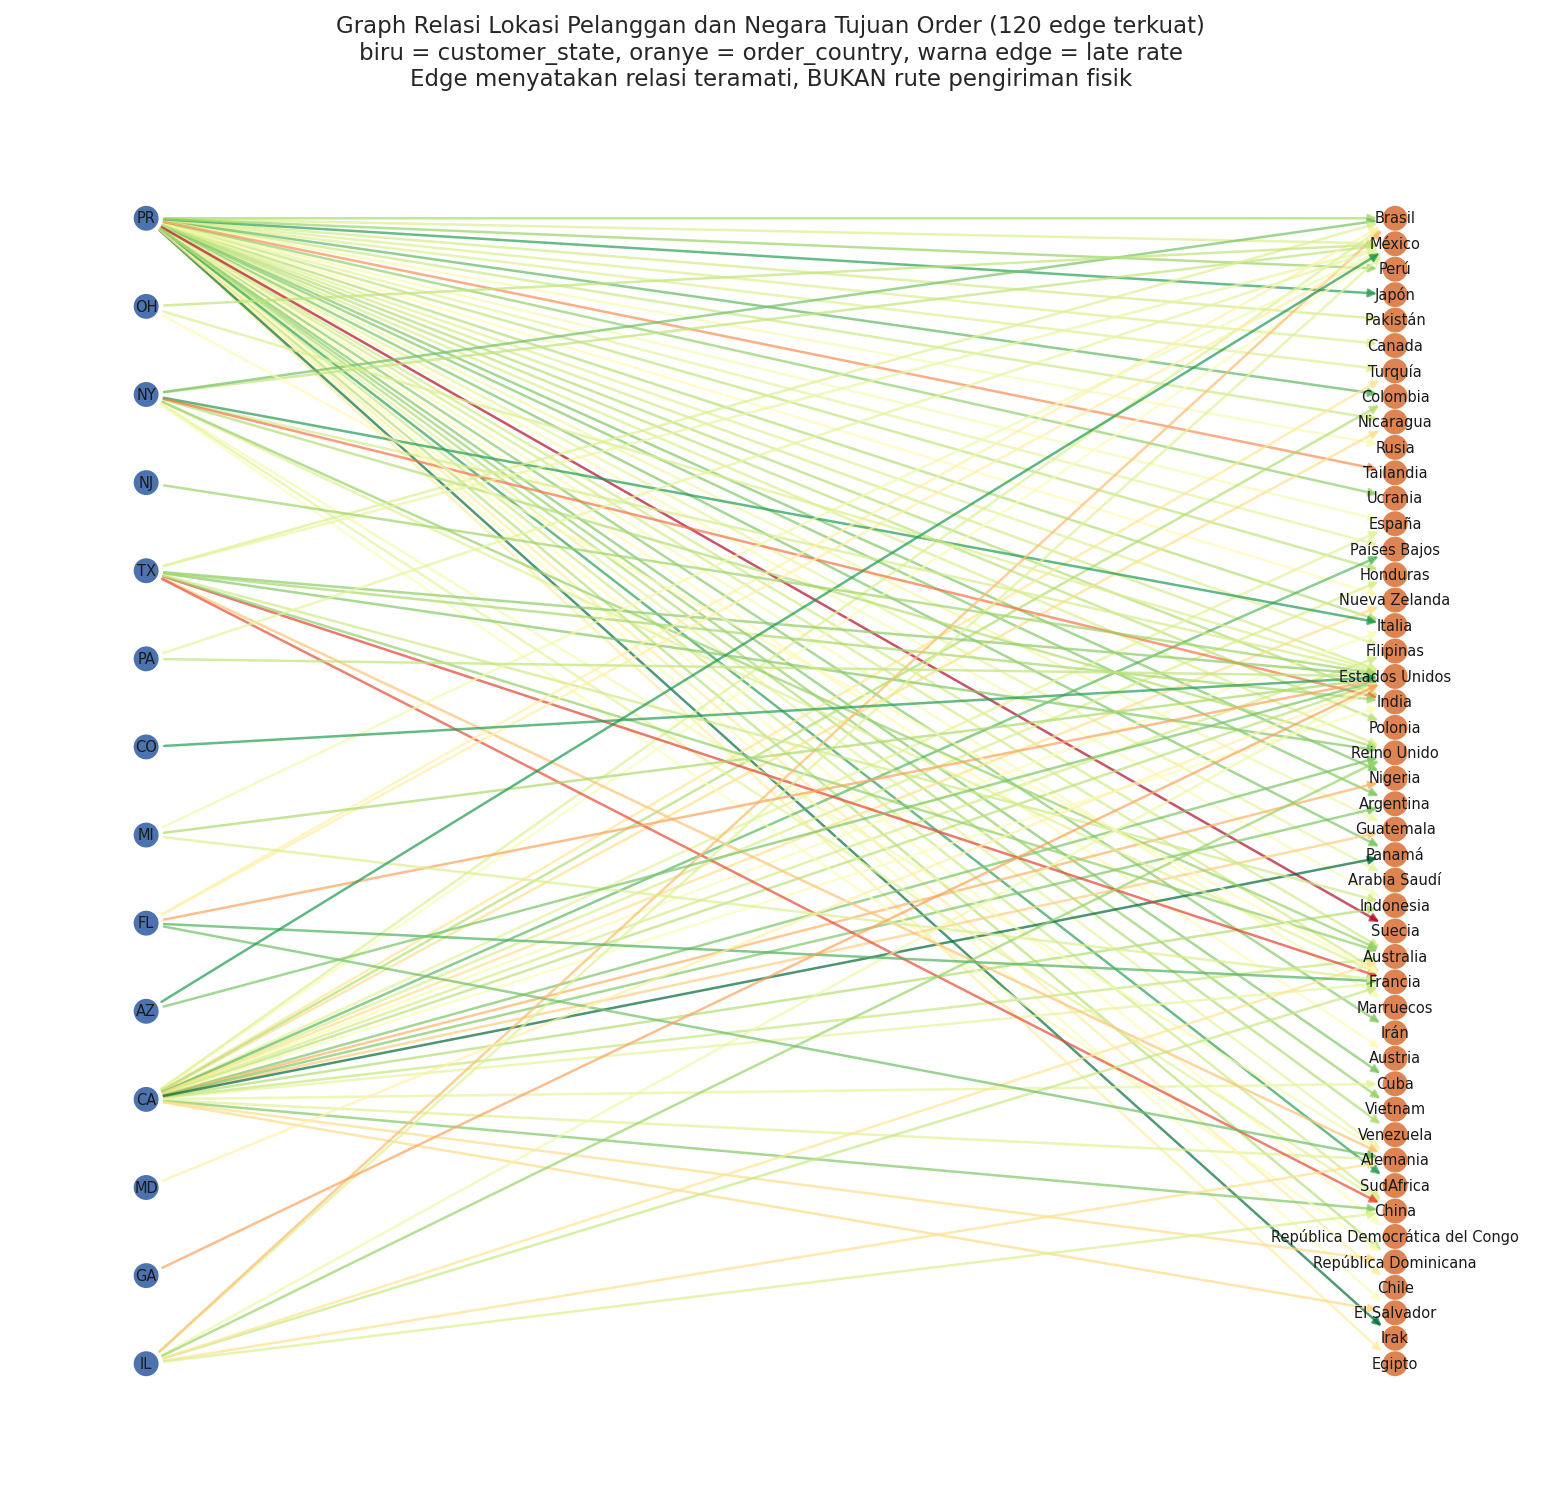

In [55]:
import networkx as nx

e1p = edges1.orderBy(F.desc("weight")).limit(120).toPandas()
G1 = nx.DiGraph()
for _, r in e1p.iterrows():
    G1.add_edge(r["src"].replace("CUST::", ""), r["dst"].replace("DEST::", ""),
                weight=int(r["weight"]), late_rate=float(r["late_rate"]))

sumber = {r["src"].replace("CUST::", "") for _, r in e1p.iterrows()}
pos1 = nx.bipartite_layout(G1, [n for n in G1.nodes() if n in sumber])

fig, ax = plt.subplots(figsize=(13, 12))
nx.draw_networkx_nodes(G1, pos1, node_size=120,
                       node_color=["#4C72B0" if n in sumber else "#DD8452" for n in G1.nodes()], ax=ax)
nx.draw_networkx_edges(G1, pos1, edge_color=[G1[u][v]["late_rate"] for u, v in G1.edges()],
                       edge_cmap=plt.cm.RdYlGn_r, edge_vmin=0.45, edge_vmax=0.70,
                       width=1.2, alpha=0.7, arrowsize=8, ax=ax)
nx.draw_networkx_labels(G1, pos1, font_size=7, ax=ax)
ax.set_title("Graph Relasi Lokasi Pelanggan dan Negara Tujuan Order (120 edge terkuat)\n"
             "biru = customer_state, oranye = order_country, warna edge = late rate\n"
             "Edge menyatakan relasi teramati, BUKAN rute pengiriman fisik", fontsize=11)
ax.axis("off")
fig.savefig(ANALYTICS + "/gambar_graph_utama.png", dpi=150, bbox_inches="tight")
plt.close("all")
display(Image(ANALYTICS + "/gambar_graph_utama.png"))

### Graph Pendukung: Analisis Market Basket Kategori

In [56]:
items = feat_df.select("order_id", "category_name").dropna().distinct()
a, b = items.alias("a"), items.alias("b")

AMBANG_EDGE_G2 = 20
edges2 = (
    a.join(b, (F.col("a.order_id") == F.col("b.order_id")) &
               (F.col("a.category_name") < F.col("b.category_name")))
     .groupBy(F.col("a.category_name").alias("src"), F.col("b.category_name").alias("dst"))
     .agg(F.count("*").alias("weight"))
     .filter(F.col("weight") >= AMBANG_EDGE_G2)
     .cache()
)
cat_stats = feat_df.groupBy("category_name").agg(
    F.count("*").alias("jumlah_order"),
    F.round(F.avg(TARGET), 4).alias("late_rate"),
)
vertices2 = (
    edges2.select(F.col("src").alias("id")).union(edges2.select(F.col("dst").alias("id"))).distinct()
    .join(cat_stats, F.col("id") == F.col("category_name"), "left").drop("category_name").cache()
)

e2 = edges2.toPandas(); v2 = vertices2.toPandas()
G2 = nx.Graph()
for _, r in v2.iterrows():
    G2.add_node(r["id"], late_rate=float(r["late_rate"]), jumlah_order=int(r["jumlah_order"]))
for _, r in e2.iterrows():
    G2.add_edge(r["src"], r["dst"], weight=int(r["weight"]))

print("Graph pendukung:", G2.number_of_nodes(), "node |", G2.number_of_edges(), "edge")
print(f"Densitas: {nx.density(G2):.4f} | rata-rata derajat: {2*G2.number_of_edges()/G2.number_of_nodes():.2f}")

Graph pendukung: 32 node | 241 edge
Densitas: 0.4859 | rata-rata derajat: 15.06


In [57]:
from networkx.algorithms import community as nx_comm

# Partisi dan modularitas dihitung dengan perlakuan bobot yang SAMA agar hasilnya konsisten.
comm_w = list(nx_comm.greedy_modularity_communities(G2, weight="weight"))
mod_w = nx_comm.modularity(G2, comm_w, weight="weight")

comm_u = list(nx_comm.greedy_modularity_communities(G2, weight=None))
mod_u = nx_comm.modularity(G2, comm_u, weight=None)

print(f"Berbobot    : {len(comm_w)} komunitas | modularitas {mod_w:.4f}")
print(f"Tanpa bobot : {len(comm_u)} komunitas | modularitas {mod_u:.4f}")
print()
print("Modularitas di bawah sekitar 0,3 lazim dianggap tidak menunjukkan struktur komunitas yang")
print("berarti. Hasil ini dilaporkan apa adanya tanpa klaim adanya kelompok kategori yang kuat.")

cent = pd.DataFrame({
    "kategori": list(G2.nodes()),
    "degree_centrality": [nx.degree_centrality(G2)[n] for n in G2.nodes()],
    "betweenness": [nx.betweenness_centrality(G2, weight="weight")[n] for n in G2.nodes()],
    "late_rate": [G2.nodes[n]["late_rate"] for n in G2.nodes()],
    "jumlah_order": [G2.nodes[n]["jumlah_order"] for n in G2.nodes()],
}).sort_values("betweenness", ascending=False).round(4)
print("\nKorelasi sentralitas terhadap late_rate:")
print(cent[["degree_centrality", "betweenness"]].corrwith(cent.late_rate).round(4).to_string())
cent.head(10)

Berbobot    : 1 komunitas | modularitas 0.0000
Tanpa bobot : 2 komunitas | modularitas 0.0641

Modularitas di bawah sekitar 0,3 lazim dianggap tidak menunjukkan struktur komunitas yang
berarti. Hasil ini dilaporkan apa adanya tanpa klaim adanya kelompok kategori yang kuat.

Korelasi sentralitas terhadap late_rate:
degree_centrality   -0.2662
betweenness         -0.0073


,kategori,degree_centrality,betweenness,late_rate,jumlah_order
2,Tennis & Racquet,0.3226,0.2452,0.5579,328
13,Electronics,0.5806,0.2419,0.5608,3156
9,Shop By Sport,0.8387,0.2204,0.5515,10984
19,Cleats,1.0000,0.1204,0.5497,24551
22,Strength Training,0.2581,0.1129,0.5766,111
21,Baseball & Softball,0.3871,0.1086,0.5522,632
24,Camping & Hiking,0.9032,0.0882,0.5453,13729
30,Hockey,0.3871,0.0548,0.5358,614
27,Cardio Equipment,0.9032,0.0419,0.5450,12487
14,Women's Golf Clubs,0.2903,0.0398,0.5359,181


In [58]:
# Uji kekokohan: apakah ketiadaan komunitas bergantung pada ambang?
uji = []
for th in [AMBANG_EDGE_G2, 50, 100, 200, 500, 1000, 2000]:
    s = e2[e2.weight >= th]
    if len(s) == 0:
        continue
    Gt = nx.Graph()
    for _, r in s.iterrows():
        Gt.add_edge(r["src"], r["dst"], weight=int(r["weight"]))
    cw = list(nx_comm.greedy_modularity_communities(Gt, weight="weight"))
    uji.append({"ambang": th, "node": Gt.number_of_nodes(), "edge": Gt.number_of_edges(),
                "densitas": round(nx.density(Gt), 4), "komunitas": len(cw),
                "modularitas": round(nx_comm.modularity(Gt, cw, weight="weight"), 4)})

uji_df = pd.DataFrame(uji)
print(f"Bobot edge minimum pada data: {int(e2.weight.min())}")
print(f"Ambang di bawah {AMBANG_EDGE_G2} tidak dapat diuji tanpa membangun ulang graph di Spark.\n")
uji_df

Bobot edge minimum pada data: 20
Ambang di bawah 20 tidak dapat diuji tanpa membangun ulang graph di Spark.



,ambang,node,edge,densitas,komunitas,modularitas
0,20,32,241,0.4859,1,0.0
1,50,27,193,0.5499,1,0.0
2,100,24,137,0.4964,1,0.0
3,200,15,83,0.7905,1,0.0
4,500,11,47,0.8545,1,0.0
5,1000,9,36,1.0000,1,0.0
6,2000,9,34,0.9444,1,0.0


### Penyiapan Data Dashboard

### Inisialisasi SparkSession

In [59]:
DASHB = ANALYTICS + "/dashboard"
os.makedirs(DASHB, exist_ok=True)

# 1. Deret waktu bulanan, keseluruhan dan per moda
(df.groupBy(F.date_format("order_ts", "yyyy-MM").alias("bulan"))
   .agg(F.count("*").alias("jumlah_order"),
        F.round(F.avg(F.col(TARGET).cast("int")), 4).alias("late_rate"),
        F.round(F.sum("sales"), 2).alias("total_sales"))
   .orderBy("bulan").toPandas().to_csv(DASHB + "/ts_bulanan.csv", index=False))

(df.groupBy(F.date_format("order_ts", "yyyy-MM").alias("bulan"), "shipping_mode")
   .agg(F.count("*").alias("jumlah_order"),
        F.round(F.avg(F.col(TARGET).cast("int")), 4).alias("late_rate"))
   .orderBy("bulan", "shipping_mode").toPandas()
   .to_csv(DASHB + "/ts_bulanan_per_mode.csv", index=False))

# 2. Matriks moda terhadap wilayah
(df.groupBy("shipping_mode", "order_region")
   .agg(F.count("*").alias("jumlah_order"),
        F.round(F.avg(F.col(TARGET).cast("int")), 4).alias("late_rate"),
        F.round(F.sum("sales"), 2).alias("total_sales"))
   .orderBy("shipping_mode", "order_region").toPandas()
   .to_csv(DASHB + "/matriks_mode_region.csv", index=False))

# 3. Seluruh negara tujuan
(df.groupBy("order_country")
   .agg(F.count("*").alias("jumlah_order"),
        F.round(F.avg(F.col(TARGET).cast("int")), 4).alias("late_rate"),
        F.round(F.sum("sales"), 2).alias("total_sales"))
   .orderBy(F.desc("jumlah_order")).toPandas()
   .to_csv(DASHB + "/tujuan_lengkap.csv", index=False))

print("Berkas deret waktu dan agregat dibuat.")

Berkas deret waktu dan agregat dibuat.


In [60]:
# 4. Geografi sisi pelanggan. Latitude/Longitude DataCo merujuk lokasi pelanggan, BUKAN tujuan.
if "Latitude" in df.columns and "Longitude" in df.columns:
    (df.groupBy("customer_country", "customer_state")
       .agg(F.count("*").alias("jumlah_order"),
            F.round(F.avg(F.col(TARGET).cast("int")), 4).alias("late_rate"),
            F.round(F.avg("Latitude"), 6).alias("lat"),
            F.round(F.avg("Longitude"), 6).alias("lon"))
       .orderBy(F.desc("jumlah_order")).toPandas()
       .to_csv(DASHB + "/geo_pelanggan.csv", index=False))
    print("geo_pelanggan.csv dibuat (koordinat = sisi pelanggan).")
    print("Untuk peta negara TUJUAN, pakai tujuan_lengkap.csv dan andalkan geocoding bawaan tool.")

# 5. Tabel yang menggabungkan hasil ML dan Graph Analytics pada tingkat kategori
kat_ml_graph = (
    cent.rename(columns={"kategori": "category_name"})
        .merge(performa_segmen("category_name").reset_index()
                 .rename(columns={"category_name": "category_name"}),
               on="category_name", how="left")
)
kat_ml_graph.to_csv(DASHB + "/kategori_ml_graph.csv", index=False)

# 6. Node dan edge graph utama, serta sentralitasnya
simpul.to_csv(DASHB + "/graph_utama_nodes.csv", index=False)
e1_all.to_csv(DASHB + "/graph_utama_edges.csv", index=False)

# 7. Performa per segmen
seg_mode.reset_index().to_csv(DASHB + "/performa_per_shipping_mode.csv", index=False)
performa_segmen("order_region").reset_index().to_csv(DASHB + "/performa_per_region.csv", index=False)
seg_bulan.reset_index().to_csv(DASHB + "/performa_per_bulan.csv", index=False)

# 8. Kurva ambang dan prediksi, untuk komponen interaktif
th_val.round(4).to_csv(DASHB + "/threshold_curve_validation.csv", index=False)

print("Isi folder dashboard:")
for f in sorted(os.listdir(DASHB)):
    print(f"  {f:<36}{os.path.getsize(DASHB+'/'+f)/1024:>8.1f} KB")

geo_pelanggan.csv dibuat (koordinat = sisi pelanggan).
Untuk peta negara TUJUAN, pakai tujuan_lengkap.csv dan andalkan geocoding bawaan tool.
Isi folder dashboard:
  geo_pelanggan.csv                        2.0 KB
  graph_utama_edges.csv                   31.9 KB
  graph_utama_nodes.csv                    9.5 KB
  kategori_ml_graph.csv                    2.6 KB
  matriks_mode_region.csv                  4.2 KB
  performa_per_bulan.csv                   0.6 KB
  performa_per_region.csv                  0.7 KB
  performa_per_shipping_mode.csv           0.3 KB
  threshold_curve_validation.csv           7.6 KB
  ts_bulanan.csv                           1.1 KB
  ts_bulanan_per_mode.csv                  4.6 KB
  tujuan_lengkap.csv                       4.7 KB


### Ekspor Output Terstandar

In [61]:
import sys, sklearn, networkx
OUT = ANALYTICS + "/output"
os.makedirs(OUT, exist_ok=True)

# --- model_metrics.csv : satu baris per model dan split
KOL = ["model", "peran", "framework", "split", "threshold", "accuracy",
       "precision_weighted", "recall_weighted", "f1_weighted",
       "precision_pos", "recall_pos", "f1_pos", "specificity", "roc_auc", "auc_pr",
       "TP", "FP", "FN", "TN", "fit_time_s", "prep_time_s", "convert_time_s"]
df_metrics = pd.DataFrame(hasil_utama)
for k in KOL:
    if k not in df_metrics.columns:
        df_metrics[k] = None
df_metrics = df_metrics[KOL]
for c in ["accuracy", "precision_weighted", "recall_weighted", "f1_weighted", "precision_pos",
          "recall_pos", "f1_pos", "specificity", "roc_auc", "auc_pr"]:
    df_metrics[c] = pd.to_numeric(df_metrics[c], errors="coerce").round(4)
df_metrics.to_csv(OUT + "/model_metrics.csv", index=False)
print("model_metrics.csv:", len(df_metrics), "baris")

# --- confusion_matrix_<model>.csv untuk model inti + baseline
import re as _re
for h in hasil_utama:
    if h["peran"] in ("inti", "baseline") and h["split"] == "chronological_test" \
       and h["framework"] in ("Spark MLlib", "—"):
        slug = _re.sub(r"[^a-z0-9]+", "_", h["model"].lower()).strip("_")
        pd.DataFrame([{"aktual": 0, "pred_0": h["TN"], "pred_1": h["FP"]},
                      {"aktual": 1, "pred_0": h["FN"], "pred_1": h["TP"]}]) \
          .to_csv(f"{OUT}/confusion_matrix_{slug}.csv", index=False)
print("confusion_matrix_*.csv dibuat.")

# --- feature_importance.csv
imp_df.round(6).to_csv(OUT + "/feature_importance.csv", index=False)

# --- threshold_selection.csv (kurva pada validation)
th_val.round(4).to_csv(OUT + "/threshold_selection_validation.csv", index=False)

model_metrics.csv: 16 baris
confusion_matrix_*.csv dibuat.


In [62]:
# --- prediction_results.csv : label, prediksi, probabilitas, dimensi aman
pred_main = (
    model_th.transform(test_v)
    .select("order_id", "order_ts", "shipping_mode", "order_region", "order_country",
            "category_name", "sched_days", "sales",
            F.col(TARGET).alias("aktual"),
            F.col("prediction").cast("int").alias("pred_ambang_050"),
            F.round(vector_to_array("probability")[1], 6).alias("prob_terlambat"))
    .withColumn("pred_ambang_f1", (F.col("prob_terlambat") >= F.lit(TH_F1)).cast("int"))
    .withColumn("pred_ambang_biaya", (F.col("prob_terlambat") >= F.lit(TH_COST)).cast("int"))
)
pred_main.toPandas().to_csv(OUT + "/prediction_results.csv", index=False)
print("prediction_results.csv:", pred_main.count(), "baris")
print("Kolom leakage tidak disertakan; hanya dimensi yang tersedia saat prediksi.")

# --- graph_nodes.csv / graph_edges.csv / graph_summary.csv (graph utama)
simpul.to_csv(OUT + "/graph_nodes.csv", index=False)
(edges1.toPandas()).to_csv(OUT + "/graph_edges.csv", index=False)
pdf_dest.to_csv(OUT + "/graph_destination_stats.csv", index=False)

gs = pd.DataFrame(graph_summary) if graph_summary else pd.DataFrame(
    [{"metrik": "jumlah_node", "nilai": vertices1.count()},
     {"metrik": "jumlah_edge", "nilai": edges1.count()}])
gs = pd.concat([gs, pd.DataFrame([
    {"metrik": "pendukung_jumlah_node", "nilai": G2.number_of_nodes()},
    {"metrik": "pendukung_jumlah_edge", "nilai": G2.number_of_edges()},
    {"metrik": "pendukung_densitas", "nilai": round(nx.density(G2), 4)},
    {"metrik": "pendukung_komunitas_berbobot", "nilai": len(comm_w)},
    {"metrik": "pendukung_modularitas_berbobot", "nilai": round(mod_w, 4)},
])], ignore_index=True)
gs.to_csv(OUT + "/graph_summary.csv", index=False)

# graph pendukung
cent.to_csv(OUT + "/graph_support_centrality.csv", index=False)
e2.to_csv(OUT + "/graph_support_edges.csv", index=False)
uji_df.to_csv(OUT + "/graph_support_threshold_test.csv", index=False)
print("Berkas graph dibuat.")

prediction_results.csv: 36256 baris
Kolom leakage tidak disertakan; hanya dimensi yang tersedia saat prediksi.
Berkas graph dibuat.


In [63]:
# --- experiment_config.json
config = {
    "target": TARGET,
    "unit_observasi": "satu baris order item pada fact_orders",
    "kelas_positif": 1,
    "seed": SEED,
    "split_utama": {
        "jenis": "chronological",
        "proporsi": {"train": 0.70, "validation": 0.10, "test": 0.20},
        "batas_train_val": str(T_TRAIN_END),
        "batas_val_test": str(T_VAL_END),
        "baris": {"train": int(n_tr), "validation": int(n_va), "test": int(n_te)},
    },
    "split_sensitivitas": {"jenis": "random", "proporsi": [0.8, 0.2], "seed": SEED},
    "fitur_kategorikal": CAT_ALL,
    "fitur_numerik": NUM_FEATURES,
    "kolom_leakage_dikecualikan": LEAKAGE,
    "model_inti": MODEL_INTI,
    "model_sekunder": ["Decision Tree"],
    "parameter_model": MODEL_PARAMS,
    "ambang": {
        "model_dipakai": MODEL_AMBANG,
        "dipilih_pada": "validation set",
        "baku": 0.5,
        "kriteria": KRITERIA,
        "f1_klasifikator_trivial": round(F1_TRIVIAL, 4),
        "rasio_biaya_fn_terhadap_fp": RASIO_FN_FP,
        "ambang_dilaporkan": {"baku": 0.5, "youden_j": TH_J, "f1_maks": TH_F1,
                              "biaya_minimum": TH_COST},
    },
    "graph_utama_metrik": {
        "node": int(len(simpul)),
        "edge": int(len(e1_all)),
        "modularitas": round(mod_u, 4),
        "jumlah_komunitas": len(komunitas_u),
    },
    "graph_utama": {
        "node_sumber": "customer_state", "node_tujuan": "order_country",
        "arah": "directed bipartite", "bobot": "jumlah order",
        "ambang_bobot_edge": AMBANG_EDGE_G1,
        "batas_interpretasi": "customer_state adalah lokasi pendaftaran pelanggan, bukan lokasi "
                              "gudang atau rute pengiriman fisik",
    },
    "graph_pendukung": {"node": "category_name", "edge": "co-occurrence pada order_id",
                        "ambang_bobot_edge": AMBANG_EDGE_G2},
    "waktu_detik": {
        "preprocessing_spark": round(PREP_FIT_TIME, 1),
        "konversi_spark_ke_pandas": round(CONVERT_TIME, 1),
        "fit_spark": {k: round(v, 1) for k, v in spark_fit_time.items()},
        "fit_sklearn": {k: round(v, 1) for k, v in sk_fit_time.items()},
    },
    "versi_library": {
        "python": sys.version.split()[0], "pyspark": spark.version,
        "scikit_learn": sklearn.__version__, "pandas": pd.__version__,
        "numpy": np.__version__, "networkx": networkx.__version__,
    },
    "graphframes_aktif": GRAPHFRAMES_OK,
}
with open(OUT + "/experiment_config.json", "w") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print(json.dumps(config, indent=2, ensure_ascii=False)[:1800])

{
  "target": "label",
  "unit_observasi": "satu baris order item pada fact_orders",
  "kelas_positif": 1,
  "seed": 42,
  "split_utama": {
    "jenis": "chronological",
    "proporsi": {
      "train": 0.7,
      "validation": 0.1,
      "test": 0.2
    },
    "batas_train_val": "1483776900.0",
    "batas_val_test": "1492806120.0",
    "baris": {
      "train": 126218,
      "validation": 18045,
      "test": 36256
    }
  },
  "split_sensitivitas": {
    "jenis": "random",
    "proporsi": [
      0.8,
      0.2
    ],
    "seed": 42
  },
  "fitur_kategorikal": [
    "shipping_mode",
    "order_region",
    "order_country",
    "market",
    "category_name",
    "department_name",
    "customer_segment",
    "payment_type",
    "price_bucket"
  ],
  "fitur_numerik": [
    "sched_days",
    "qty",
    "sales",
    "unit_price",
    "discount_rate",
    "order_year",
    "order_month",
    "order_dayofweek",
    "order_hour",
    "is_weekend",
    "line_total",
    "discount_amount"
  ]